# Underlyings daily data - EDA tables and charts

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
assert OUT.exists(), "outputs/ not found - run scripts/01..04 first"
pd.set_option("display.max_columns", 80, "display.width", 250, "display.max_colwidth", 80, "display.float_format", "{:,.5g}".format)


def table(rel, max_rows=60, head=30):
    df = pd.read_csv(OUT / rel, encoding="utf-8-sig")
    print(f"{rel}  [{len(df)} rows x {df.shape[1]} cols]")
    display(df if len(df) <= max_rows else df.head(head))


def kv(rel):
    data = json.loads((OUT / rel).read_text(encoding="utf-8"))
    print(rel)
    display(pd.Series(data, dtype=object).rename("value").to_frame())


def image(rel):
    display(Image(filename=str(OUT / rel)))


## Step 0 - Load and reconcile the input files

### step0_overview/summary.json

In [2]:
kv("step0_overview/summary.json")

step0_overview/summary.json


,value
rows,17368
columns,39
symbols,27
market_days,718
first_day,2023-11-08
last_day,2026-11-07
halted_rows,2452
adj_events,69
reconciliation_checks,272
reconciliation_mismatches,0


### step0_overview/columns_dictionary.csv

In [3]:
table("step0_overview/columns_dictionary.csv")

step0_overview/columns_dictionary.csv  [39 rows x 10 cols]


,column,group,dtype,n_null,pct_null,n_unique,min,max,example,description_inferred
0,symbol,identity,str,0,0,27,NaN,NaN,اخابر,"Ticker (Persian text, Arabic ي/ك variants present)"
1,name,identity,str,0,0,27,NaN,NaN,اخابر,Instrument name - identical to symbol in this file
2,ins_code,identity,int64,0,0,27,7.7825e+14,7.1484e+16,22811176775480091,Exchange instrument code (unique id per symbol)
3,date,date,datetime64[us],0,0,718,NaN,NaN,2023-11-08 00:00:00,Gregorian trading date
4,date_jalali,date,str,0,0,718,NaN,NaN,1402-08-17,"Jalali (Solar Hijri) trading date, YYYY-MM-DD"
5,open,raw_price,float64,0,0,7364,0,4.256e+05,9760.0,First trade price of the day (0 on halted days)
6,high,raw_price,float64,0,0,7757,0,4.256e+05,10060.0,Highest trade price (0 on halted days)
7,low,raw_price,float64,0,0,7608,0,4.1e+05,9760.0,Lowest trade price (0 on halted days)
8,last_price,raw_price,float64,0,0,7960,280,4.139e+05,9830.0,Last trade price
9,final_price,raw_price,float64,0,0,8331,277,4.14e+05,9910.0,Closing/settlement price (volume-weighted on TSE; not guaranteed inside [low...


### step0_overview/market_calendar.csv

In [4]:
table("step0_overview/market_calendar.csv")

step0_overview/market_calendar.csv  [718 rows x 4 cols]


,date,symbols_with_record,symbols_halted,symbols_traded
0,2023-11-08,21,1,20
1,2023-11-11,21,1,20
2,2023-11-12,21,3,18
3,2023-11-13,21,2,19
4,2023-11-14,21,1,20
5,2023-11-15,21,1,20
6,2023-11-18,21,2,19
7,2023-11-19,21,2,19
8,2023-11-20,21,2,19
9,2023-11-21,21,1,20


### step0_overview/reconciliation.csv

In [5]:
table("step0_overview/reconciliation.csv")

step0_overview/reconciliation.csv  [272 rows x 5 cols]


,section,item,reported,recomputed,match
0,headline,symbols,27,27,True
1,headline,total_rows,17368,17368,True
2,headline,market_days_union,718,718,True
3,headline,first_market_day,2023-11-08,2023-11-08,True
4,headline,last_market_day,2026-11-07,2026-11-07,True
5,headline,halted_rows_total,2452,2452,True
6,headline,adj_events_total,69,69,True
7,halted_per_symbol,دزاگرس,299,299,True
8,halted_per_symbol,خودرو,136,136,True
9,halted_per_symbol,وبصادر,128,128,True


### step0_overview/symbol_overview.csv

In [6]:
table("step0_overview/symbol_overview.csv")

step0_overview/symbol_overview.csv  [27 rows x 12 cols]


,symbol,ins_code,first_date,last_date,rows,expected_rows_from_first_date,missing_market_days,halted_days,halted_pct,active_days,adj_events,starts_after_window_start
0,اخابر,22811176775480091,2023-11-08,2026-11-07,718,718,0,111,15.5,607,4,False
1,اطلس,11427939669935844,2023-11-08,2026-11-07,717,718,1,62,8.6,655,1,False
2,اهرم,17914401175772326,2023-11-08,2026-11-07,718,718,0,59,8.2,659,0,False
3,بساما,41625340598198551,2023-11-08,2026-11-07,717,718,1,79,11,638,3,False
4,تاصيكو,23293437377896568,2023-11-08,2026-11-07,718,718,0,79,11,639,6,False
5,تاپيكو,22560050433388046,2023-11-08,2026-11-07,718,718,0,92,12.8,626,3,False
6,توان,41927452991671109,2023-11-08,2026-11-07,717,718,1,59,8.2,658,0,False
7,خبهمن,26824673819862694,2023-11-08,2026-11-07,718,718,0,82,11.4,636,3,False
8,خساپا,44891482026867833,2023-11-08,2026-11-07,718,718,0,120,16.7,598,1,False
9,خودرو,65883838195688438,2023-11-08,2026-11-07,718,718,0,136,18.9,582,1,False


### step0_overview/coverage_heatmap.png

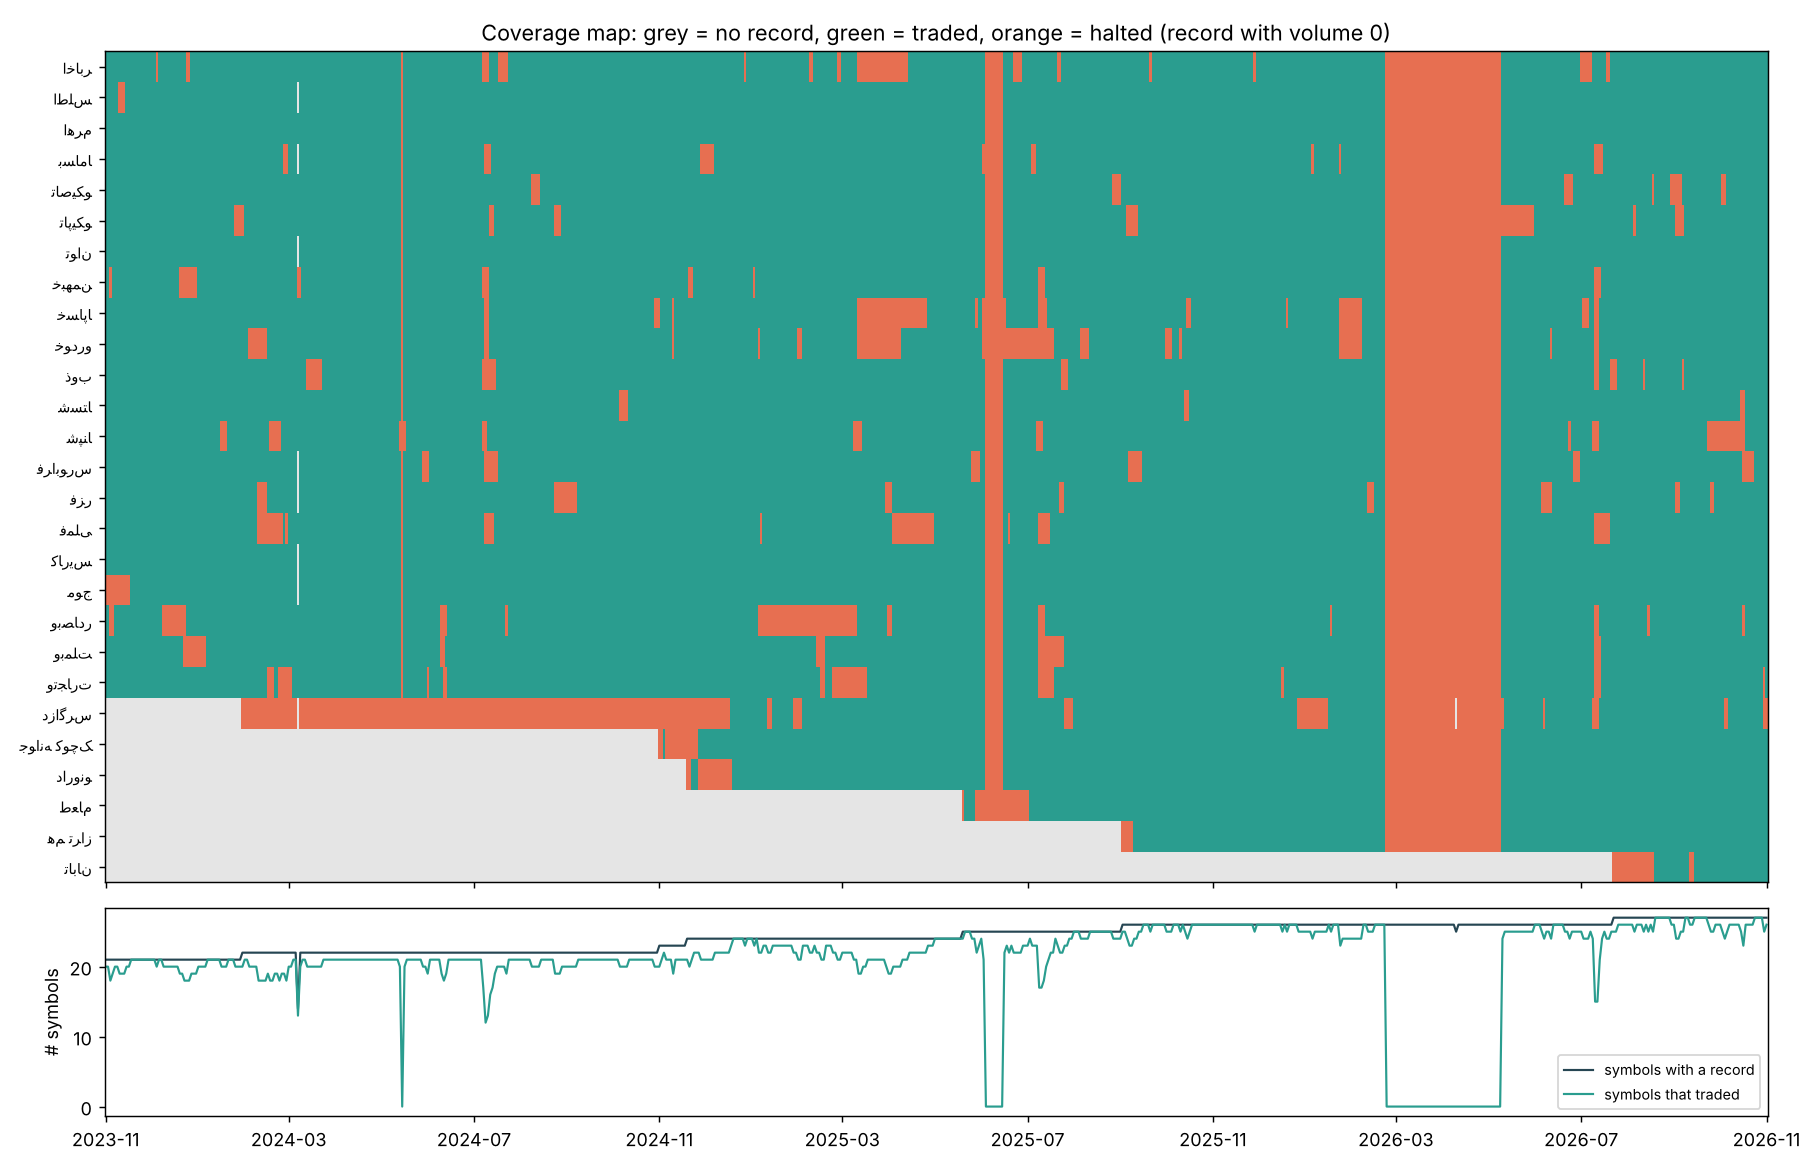

In [7]:
image("step0_overview/coverage_heatmap.png")

## Step 1 - Structural validation

### step1_structure/summary.json

In [8]:
kv("step1_structure/summary.json")

step1_structure/summary.json


,value
checks,18
PASS,12
INFO,3
WARN,3


### step1_structure/checks_summary.csv

In [9]:
table("step1_structure/checks_summary.csv")

step1_structure/checks_summary.csv  [18 rows x 5 cols]


,id,check,status,n_issues,detail
0,S1.01,column set equals the 39 documented columns,PASS,0,"rows=17368, cols=39, missing=[], extra=[]"
1,S1.02,"numeric columns are numeric, flags are boolean",PASS,0,bad=[]; *_count columns are float only because of NaN on halted rows
2,S1.03,nulls only in flow columns on halted rows (+ event_type off-event),PASS,0,flow columns null on 2416 of 2452 halted rows; the other 36 halted rows carr...
3,S1.03b,event_type is filled exactly when adj_event is True,PASS,0,NaN
4,S1.03c,is_halted == (volume==0 or trade_count==0),PASS,0,volume==0 and trade_count==0 coincide on 17368 rows
5,S1.04,"no duplicate (symbol,date) / (ins_code,date) / full rows",PASS,0,"symbol-date=0, code-date=0, full-row=0"
6,S1.05,symbol <-> ins_code is 1:1,PASS,0,27 symbols / 27 codes
7,S1.05b,name column adds no information (name == symbol),INFO,0,safe to drop `name` downstream
8,S1.06,symbols use Arabic ي/ك: normalize before joining with the options file,WARN,5,"5 symbols change after normalization, 0 collisions; 2 symbols contain a space"
9,S1.07,dates parse and the file is sorted by date within each symbol,PASS,0,2023-11-08 .. 2026-11-07


### step1_structure/gap_dates.csv

In [10]:
table("step1_structure/gap_dates.csv")

step1_structure/gap_dates.csv  [2 rows x 4 cols]


,date,n_listed,n_missing,missing_symbols
0,2024-03-09,22,8,اطلس بساما توان دزاگرس فرابورس فزر كاريس موج
1,2026-04-21,26,1,دزاگرس


### step1_structure/halted_breakdown_by_symbol.csv

In [11]:
table("step1_structure/halted_breakdown_by_symbol.csv")

step1_structure/halted_breakdown_by_symbol.csv  [27 rows x 7 cols]


,symbol,halted_total,halted_in_market_closure,halted_symbol_specific,rows,rows_excl_closure,symbol_specific_halt_pct
0,دزاگرس,299,58,241,657,599,40.2
1,خودرو,136,59,77,718,659,11.7
2,وبصادر,128,59,69,718,659,10.5
3,خساپا,120,59,61,718,659,9.3
4,اخابر,111,59,52,718,659,7.9
5,فملي,107,59,48,718,659,7.3
6,وتجارت,100,59,41,718,659,6.2
7,شپنا,98,59,39,718,659,5.9
8,تاپيكو,92,59,33,718,659,5
9,فزر,90,59,31,717,658,4.7


### step1_structure/jalali_mismatches.csv

In [12]:
table("step1_structure/jalali_mismatches.csv")

step1_structure/jalali_mismatches.csv  [0 rows x 4 cols]


,symbol,date,date_jalali,expected_jalali


### step1_structure/market_wide_closures.csv

In [13]:
table("step1_structure/market_wide_closures.csv")

step1_structure/market_wide_closures.csv  [3 rows x 4 cols]


,start,end,market_days,min_halted_share
0,2024-05-20,2024-05-20,1,1
1,2025-06-15,2025-06-25,8,1
2,2026-02-28,2026-05-18,50,1


### step1_structure/null_summary.csv

In [14]:
table("step1_structure/null_summary.csv")

step1_structure/null_summary.csv  [15 rows x 5 cols]


,column,n_null,pct_null,n_null_on_halted_rows,n_null_on_active_rows
0,event_type,17299,99.6,2413,14886
1,ind_buy_vol,2416,13.91,2416,0
2,ind_sell_vol,2416,13.91,2416,0
3,ind_buy_val,2416,13.91,2416,0
4,ind_sell_val,2416,13.91,2416,0
5,ind_buy_count,2416,13.91,2416,0
6,ind_sell_count,2416,13.91,2416,0
7,corp_buy_vol,2416,13.91,2416,0
8,corp_sell_vol,2416,13.91,2416,0
9,corp_buy_val,2416,13.91,2416,0


### step1_structure/symbol_normalization_map.csv

In [15]:
table("step1_structure/symbol_normalization_map.csv")

step1_structure/symbol_normalization_map.csv  [27 rows x 4 cols]


,symbol_raw,symbol_normalized,changed,has_space
0,اخابر,اخابر,False,False
1,اطلس,اطلس,False,False
2,اهرم,اهرم,False,False
3,بساما,بساما,False,False
4,تابان,تابان,False,False
5,تاصيكو,تاصیکو,True,False
6,تاپيكو,تاپیکو,True,False
7,توان,توان,False,False
8,جوانه كوچك,جوانه کوچک,True,True
9,خبهمن,خبهمن,False,False


### step1_structure/weekday_counts.csv

In [16]:
table("step1_structure/weekday_counts.csv")

step1_structure/weekday_counts.csv  [5 rows x 2 cols]


,weekday,rows
0,Saturday,3522
1,Tuesday,3510
2,Monday,3489
3,Sunday,3464
4,Wednesday,3383


## Step 2 - Price / volume / flow consistency

### step2_consistency/summary.json

In [17]:
kv("step2_consistency/summary.json")

step2_consistency/summary.json


,value
checks,20
PASS,9
WARN,7
INFO,3
FAIL,1
large_moves,"{'market_wide_move': 29, 'reopen_after_halt': 24, 'wide_band_month': 14, 'ad..."


### step2_consistency/checks_summary.csv

In [18]:
table("step2_consistency/checks_summary.csv")

step2_consistency/checks_summary.csv  [20 rows x 5 cols]


,id,check,status,n_issues,detail
0,S2.01,active rows: all prices and prev_final > 0,PASS,0,{}
1,S2.02,"halted rows: high/low are 0 (not NaN), open is 0",WARN,12,high==low==0 on 2452/2452 halted rows; open != 0 on 12 halted rows (stale va...
2,S2.03,halted rows: last_price/final_price carried forward and > 0,PASS,0,final_price == prev_final on 100.0% of halted rows
3,S2.04,"OHLC order: high>=low, open/last inside [low, high]",FAIL,6,"{'high<low': 0, 'open>high': 3, 'open<low': 3, 'last>high': 0, 'last<low': 0..."
4,S2.05,"final_price lies inside [low, high]",WARN,426,"261 above high, 165 below low (2.9% of active rows); max overshoot 4.00% ; 1..."
5,S2.06,"value/volume (VWAP) lies inside [low, high] (tol 0.1%)",PASS,0,NaN
6,S2.07,final_price is (almost) the day's VWAP,INFO,NaN,"median |final/vwap-1| = 1.02e-04, p99 = 1.74%; on the 426 rows where final i..."
7,S2.08,prev_final == previous record's final_price (except on adj_event days),WARN,3,"17341 comparable rows, 72 differ, 69 explained by adj_event; unexplained: بس..."
8,S2.09,adj_ratio == prev_final / previous final_price on event days,PASS,0,max abs deviation 4.9e-07
9,S2.10,adj_* == raw * adj_factor on active rows (tol 0.0001),PASS,0,"max rel dev: adj_open=2.3e-07, adj_high=2.2e-07, adj_low=2.3e-07, adj_last=2..."


### step2_consistency/adj_event_review.csv

In [19]:
table("step2_consistency/adj_event_review.csv")

step2_consistency/adj_event_review.csv  [69 rows x 16 cols]


,symbol,date,event_type,adj_ratio,prev_final,prev_row_final,final_price,ret_vs_reference,raw_ret_unadjusted,adj_ret,adj_minus_reference,factor_before,factor_after,prev_row_halted,is_halted,review_flags
0,اخابر,2024-07-22,dividend_or_adjustment,0.95395,"7,250","7,600","7,250",0,-0.046053,5.057e-07,5.057e-07,0.052038,0.05455,True,False,NaN
1,اخابر,2025-04-06,capital_increase,0.0625,530,"8,480",530,0,-0.9375,0,0,0.05455,0.8728,True,True,very_small_ratio
2,اخابر,2025-07-09,dividend_or_adjustment,0.93631,588,628,588,0,-0.063694,-1.8244e-07,-1.8244e-07,0.8728,0.93218,True,True,NaN
3,اخابر,2026-07-18,dividend_or_adjustment,0.93218,646,693,646,0,-0.067821,0,0,0.93218,1,True,True,NaN
4,اطلس,2023-11-21,capital_increase,0.1,"40,606",4.0606e+05,"40,306",-0.0073881,-0.90074,-0.0073905,-2.4445e-06,0.1,1,True,False,very_small_ratio
5,بساما,2024-07-23,dividend_or_adjustment,0.9744,"11,420","11,720","11,240",-0.015762,-0.040956,-0.015762,-2.5884e-07,0.40348,0.41408,True,False,NaN
6,بساما,2024-12-11,capital_increase,0.41637,"5,900","14,170","5,900",0,-0.58363,-9.2032e-07,-9.2032e-07,0.41408,0.9945,True,True,NaN
7,بساما,2026-07-27,dividend_or_adjustment,0.9945,"9,040","9,090","9,230",0.021018,0.015402,0.021018,4.6307e-07,0.9945,1,True,False,NaN
8,تابان,2026-09-23,dividend_or_adjustment,0.96835,"18,660","19,270","20,570",0.10236,0.067462,0.10236,-4.8442e-07,0.96835,1,True,False,big_move_on_event_day
9,تاصيكو,2024-08-24,capital_increase,0.8956,"8,150","9,100","8,150",0,-0.1044,4.4114e-07,4.4114e-07,0.57294,0.63973,True,True,NaN


### step2_consistency/flow_inconsistencies.csv

In [20]:
table("step2_consistency/flow_inconsistencies.csv")

step2_consistency/flow_inconsistencies.csv  [252 rows x 13 cols]


,symbol,date,volume,value,ind_buy_vol,corp_buy_vol,ind_sell_vol,corp_sell_vol,ind_buy_val,corp_buy_val,ind_sell_val,corp_sell_val,rule
0,اطلس,2023-11-29,7.0473e+06,2.9156e+11,6.4775e+06,5.6953e+05,2.7611e+06,4.286e+06,2.6816e+11,2.3396e+10,1.1459e+11,1.7696e+11,buy_vol != volume
1,اطلس,2023-12-02,4.4368e+06,1.8732e+11,4.2466e+06,1.8814e+05,2.1811e+06,2.2536e+06,1.7936e+11,7.8709e+09,9.1862e+10,9.5371e+10,buy_vol != volume
2,اطلس,2023-12-05,1.1145e+06,4.7814e+10,1.0773e+06,"36,548",1.0796e+06,"34,237",4.6217e+10,1.5665e+09,4.6315e+10,1.4685e+09,buy_vol != volume
3,اطلس,2023-12-09,2.4899e+06,1.0588e+11,3.6315e+05,2.1267e+06,2.4712e+06,"18,655",1.5445e+10,9.0436e+10,1.0509e+11,7.9492e+08,buy_vol != volume
4,اطلس,2024-02-05,5.1878e+05,2.1724e+10,4.5694e+05,"61,489",4.8968e+05,"28,748",1.9133e+10,2.5765e+09,2.0506e+10,1.2034e+09,buy_vol != volume
5,اطلس,2024-02-07,7.5765e+05,3.167e+10,4.3769e+05,3.1994e+05,6.9575e+05,"61,879",1.8314e+10,1.3355e+10,2.9085e+10,2.5833e+09,buy_vol != volume
6,اهرم,2025-05-10,1.3462e+08,4.0274e+12,9.5945e+07,3.8714e+07,1.2017e+08,1.4486e+07,2.8703e+12,1.1581e+12,3.5954e+12,4.33e+11,buy_vol != volume
7,بساما,2023-11-25,1.2119e+07,1.159e+11,1.1702e+07,3.9681e+05,6.0951e+06,6.0038e+06,1.1206e+11,3.6504e+09,5.7908e+10,5.7807e+10,buy_vol != volume
8,بساما,2024-02-05,1.5305e+06,1.66e+10,2.7925e+05,1.2441e+06,1.4134e+06,1.1e+05,3.0049e+09,1.3518e+10,1.5339e+10,1.1836e+09,buy_vol != volume
9,تابان,2026-08-31,5.9999e+09,7.6799e+13,5.9938e+09,6.1922e+06,0,6e+09,7.672e+13,7.926e+10,0,7.68e+13,buy_vol != volume


### step2_consistency/large_moves.csv

In [21]:
table("step2_consistency/large_moves.csv")

step2_consistency/large_moves.csv  [78 rows x 14 cols]


,symbol,date,open,high,low,final_price,prev_final,ret,adj_event,prev_row_halted,day_share_moving_5pct,wide_band_month,volume,class
0,اخابر,2023-11-26,"9,900","10,170","9,800","10,160","9,510",0.068349,False,False,0.047619,True,1.1934e+08,wide_band_month
1,اخابر,2023-12-03,"11,000","11,810","10,800","11,740","11,040",0.063406,False,False,0.047619,True,2.3111e+08,wide_band_month
2,اخابر,2023-12-16,"11,860","12,560","11,860","12,490","11,740",0.063884,False,False,0.05,True,1.4355e+08,wide_band_month
3,اخابر,2024-02-05,"10,540","11,100","10,370","11,070","10,380",0.066474,False,False,0.05,True,7.9311e+07,wide_band_month
4,اخابر,2024-02-14,"11,450","11,450","11,160","11,420","10,710",0.066293,False,False,0.055556,True,1.7991e+08,wide_band_month
5,اخابر,2024-04-13,"10,110","10,110","9,580","9,630","10,300",-0.065049,False,False,0.33333,True,4.0081e+07,market_wide_move
6,اخابر,2025-04-27,670,690,650,662,530,0.24906,False,True,0.045455,False,4.9543e+09,reopen_after_halt
7,اطلس,2024-07-06,"46,000","46,158","44,302","45,640","41,962",0.087651,False,False,0.71429,True,9.2945e+06,market_wide_move
8,اهرم,2024-04-13,"22,070","22,070","20,950","21,340","22,710",-0.060326,False,False,0.33333,True,2.1263e+08,market_wide_move
9,اهرم,2024-04-20,"22,800","23,930","22,800","23,530","21,760",0.081342,False,False,0.61905,True,2.9475e+08,market_wide_move


### step2_consistency/monthly_move_band.csv

In [22]:
table("step2_consistency/monthly_move_band.csv")

step2_consistency/monthly_move_band.csv  [35 rows x 6 cols]


,month,n_rows,max_abs,p995_abs,n_above_3pct,n_above_4pct
0,2023-11,295,0.07304,0.06634,16,9
1,2023-12,418,0.06388,0.06118,44,23
2,2024-01,462,0.05014,0.04615,25,9
3,2024-02,337,0.06647,0.05488,9,4
4,2024-03,352,0.07049,0.06855,55,35
5,2024-04,420,0.09139,0.08026,60,42
6,2024-05,355,0.06549,0.05945,39,17
7,2024-06,362,0.05822,0.05544,29,8
8,2024-07,374,0.1,0.09997,69,45
9,2024-08,390,0.0815,0.06359,15,12


### step2_consistency/ohlc_violations.csv

In [23]:
table("step2_consistency/ohlc_violations.csv")

step2_consistency/ohlc_violations.csv  [432 rows x 12 cols]


,symbol,date,open,high,low,last_price,final_price,prev_final,volume,adj_event,rule,rel_violation
0,طعام,2025-10-29,"12,230","12,145","11,914","12,000","12,142","11,914",4.1443e+06,False,open>high,0.0069988
1,طعام,2025-12-29,"15,159","15,100","14,435","15,000","14,786","14,742",1.3402e+05,False,open>high,0.0039073
2,طعام,2026-01-07,"15,865","15,864","15,103","15,175","15,702","15,403",1.791e+06,False,open>high,6.3036e-05
3,طعام,2025-07-23,"10,150","10,598","10,331","10,400","10,391","10,293",1.2783e+05,False,open<low,0.017833
4,طعام,2025-12-08,"13,270","13,700","13,659","13,659","13,668","13,429","2,200",False,open<low,0.029314
5,طعام,2025-12-31,"14,520","14,881","14,670","14,881","14,778","14,448",2.5917e+05,False,open<low,0.010331
6,اخابر,2024-04-14,"9,540","9,540","9,540","9,540","9,620","9,630",1.849e+06,False,final>high,0.0083857
7,اخابر,2024-04-16,"9,590","9,590","9,590","9,590","9,640","9,680",4.9862e+06,False,final>high,0.0052138
8,اخابر,2024-05-26,"7,810","7,810","7,810","7,810","7,920","7,960",4.0298e+06,False,final>high,0.014085
9,اخابر,2024-05-27,"7,770","7,770","7,770","7,770","7,870","7,920",5.2671e+06,False,final>high,0.01287


### step2_consistency/prev_final_continuity.csv

In [24]:
table("step2_consistency/prev_final_continuity.csv")

step2_consistency/prev_final_continuity.csv  [72 rows x 9 cols]


,symbol,date,prev_final,prev_row_final,rel_diff,adj_event,adj_ratio,is_halted,class
0,اخابر,2024-07-22,"7,250","7,600",-0.046053,True,0.95395,False,explained_by_adj_event
1,اخابر,2025-04-06,530,"8,480",-0.9375,True,0.0625,True,explained_by_adj_event
2,اخابر,2025-07-09,588,628,-0.063694,True,0.93631,True,explained_by_adj_event
3,اخابر,2026-07-18,646,693,-0.067821,True,0.93218,True,explained_by_adj_event
4,اطلس,2023-11-21,"40,606",4.0606e+05,-0.9,True,0.1,False,explained_by_adj_event
5,بساما,2024-07-23,"11,420","11,720",-0.025597,True,0.9744,False,explained_by_adj_event
6,بساما,2024-12-11,"5,900","14,170",-0.58363,True,0.41637,True,explained_by_adj_event
7,بساما,2025-07-20,"8,040","8,060",-0.0024814,False,1,False,UNEXPLAINED_small(<1%)
8,بساما,2026-07-27,"9,040","9,090",-0.0055006,True,0.9945,False,explained_by_adj_event
9,تابان,2026-09-23,"18,660","19,270",-0.031655,True,0.96835,False,explained_by_adj_event


### step2_consistency/return_extremes_by_symbol.csv

In [25]:
table("step2_consistency/return_extremes_by_symbol.csv")

step2_consistency/return_extremes_by_symbol.csv  [27 rows x 9 cols]


,symbol,n_active_days,mean,std,min,p01,p99,max,n_moves_above_threshold
0,اخابر,607,0.00158,0.02451,-0.06505,-0.04199,0.05937,0.24906,7
1,اطلس,655,0.00241,0.01728,-0.03967,-0.02999,0.03,0.08765,1
2,اهرم,659,0.00247,0.02544,-0.06952,-0.04,0.04466,0.1,5
3,بساما,638,0.00174,0.01537,-0.05484,-0.0392,0.04351,0.0482,0
4,تابان,47,0.26554,1.7192,-0.02994,-0.02971,6.4191,11.8,2
5,تاصيكو,639,0.0036,0.01908,-0.04691,-0.02998,0.03055,0.11979,2
6,تاپيكو,626,0.00231,0.02002,-0.05729,-0.03576,0.0448,0.10037,3
7,توان,658,0.00258,0.02574,-0.07095,-0.03999,0.04022,0.09999,5
8,جوانه كوچك,405,0.00354,0.01969,-0.02999,-0.02995,0.02999,0.099,1
9,خبهمن,636,0.00132,0.02165,-0.06141,-0.04162,0.04836,0.0827,4


### step2_consistency/return_thresholds.csv

In [26]:
table("step2_consistency/return_thresholds.csv")

step2_consistency/return_thresholds.csv  [8 rows x 3 cols]


,threshold,n_rows_above,n_non_event_rows_above
0,0.05,140,132
1,0.06,78,70
2,0.07,40,33
3,0.08,33,26
4,0.1,17,15
5,0.15,10,9
6,0.3,5,4
7,1,2,2


### step2_consistency/vwap_violations.csv

In [27]:
table("step2_consistency/vwap_violations.csv")

step2_consistency/vwap_violations.csv  [0 rows x 8 cols]


,symbol,date,low,high,vwap,final_price,volume,value


### step2_consistency/large_moves_by_class.png

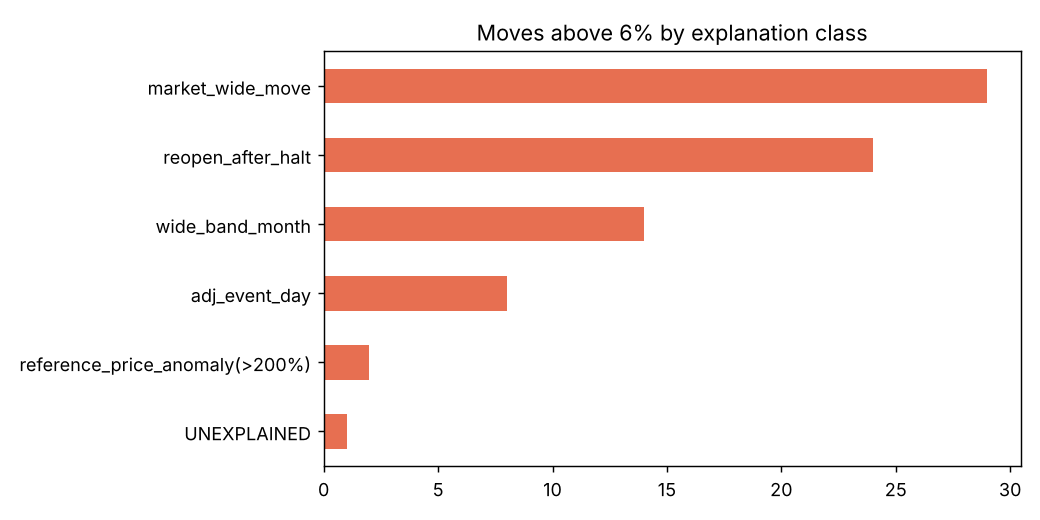

In [28]:
image("step2_consistency/large_moves_by_class.png")

### step2_consistency/return_distribution.png

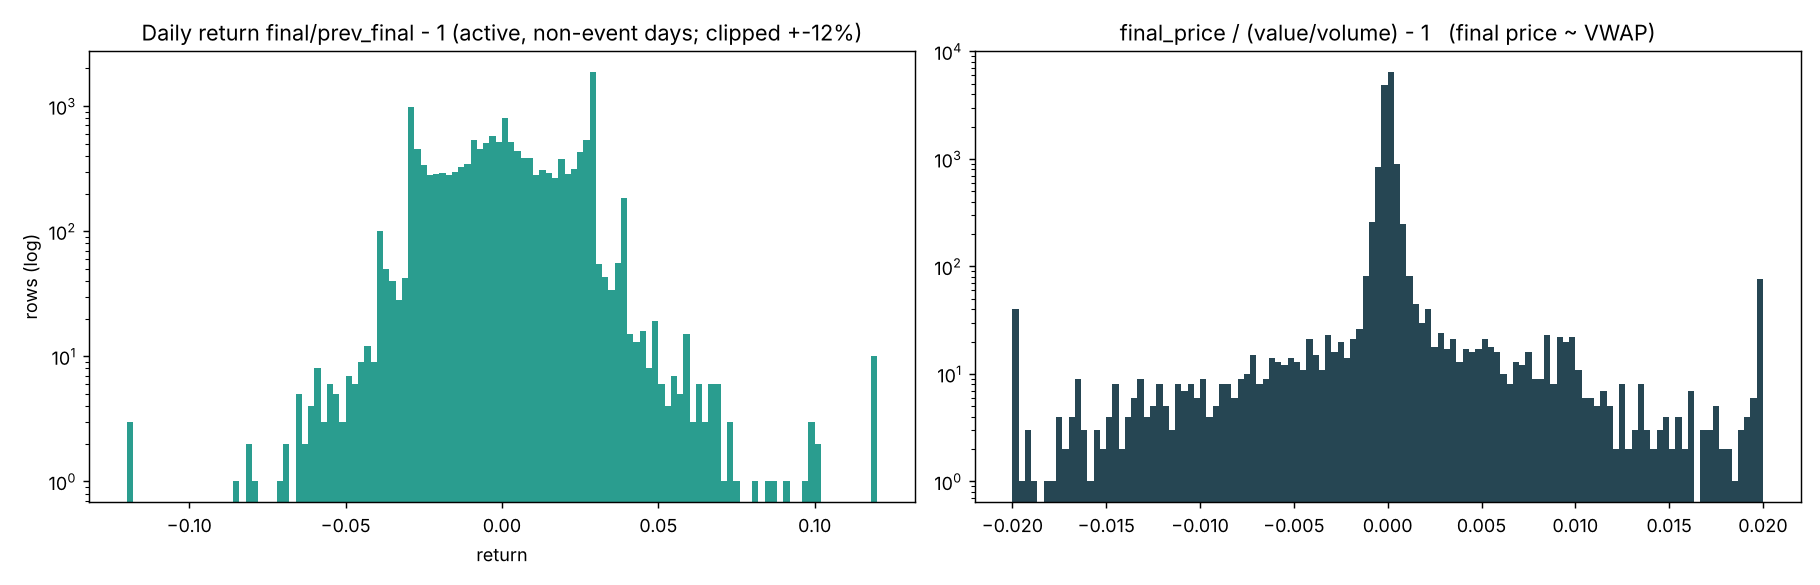

In [29]:
image("step2_consistency/return_distribution.png")

## Step 3 - Halted days and gaps

### step3_halts_gaps/summary.json

In [30]:
kv("step3_halts_gaps/summary.json")

step3_halts_gaps/summary.json


,value
checks,10
WARN,6
PASS,2
INFO,2
status_cells,"{'ACTIVE': 14916, 'MARKET_CLOSED': 1522, 'HALT_SYMBOL': 931, 'NO_RECORD': 8}"


### step3_halts_gaps/checks_summary.csv

In [31]:
table("step3_halts_gaps/checks_summary.csv")

step3_halts_gaps/checks_summary.csv  [10 rows x 5 cols]


,id,check,status,n_issues,detail
0,S3.01,halt runs partition all halted rows,PASS,0,"221 runs cover 2452 of 2452 halted rows; kinds: {'symbol_only': 148, 'market..."
1,S3.02,symbol-specific halt runs: length distribution,INFO,156,"{'2-3': 63, '4-10': 41, '1': 34, '>10': 18}; runs >10 symbol-days = 18 holdi..."
2,S3.03,every adjustment event sits on a halted day or on the reopen day,PASS,0,"69 events: 39 on halted rows, 30 on the first active day after a halt, 0 els..."
3,S3.04,share of symbol-specific halt runs tied to a corporate action,INFO,61,61/156 runs (39%); among runs >3 symbol-days: 37/59
4,S3.05,reopen day after a halt behaves differently from an ordinary day,WARN,220,"median |ret|: baseline 1.76%, after short halt (<=3d) 2.82%, after long halt..."
5,S3.06,symbols with < 80% active days on their tradable calendar,WARN,2,تابان 70% (first active 2026-08-31); دزاگرس 60% (first active 2024-12-23)
6,S3.07,symbols whose longest active streak is shorter than 60 days,WARN,1,تابان=32
7,S3.08,missing records (NO_RECORD) outside market closures,WARN,8,"{'2024-03-09': 8}; neighbours: prev={'ACTIVE': 7, 'HALT_SYMBOL': 1}, next={'..."
8,S3.09,symbols whose first real trade comes >30 days after their first record,WARN,1,دزاگرس: record 2024-01-31 -> first trade 2024-12-23
9,S3.10,raw volume jumps after capital increases (volume is NOT adjusted like prices),WARN,33,"33 capital-increase events: corr(log expected 1/ratio, log observed volume m..."


### step3_halts_gaps/gap_context.csv

In [32]:
table("step3_halts_gaps/gap_context.csv")

step3_halts_gaps/gap_context.csv  [8 rows x 4 cols]


,symbol,date,prev_status,next_status
0,اطلس,2024-03-09,ACTIVE,ACTIVE
1,بساما,2024-03-09,ACTIVE,ACTIVE
2,توان,2024-03-09,ACTIVE,ACTIVE
3,دزاگرس,2024-03-09,HALT_SYMBOL,HALT_SYMBOL
4,فرابورس,2024-03-09,ACTIVE,ACTIVE
5,فزر,2024-03-09,ACTIVE,ACTIVE
6,كاريس,2024-03-09,ACTIVE,ACTIVE
7,موج,2024-03-09,ACTIVE,ACTIVE


### step3_halts_gaps/halt_run_summary_by_symbol.csv

In [33]:
table("step3_halts_gaps/halt_run_summary_by_symbol.csv")

step3_halts_gaps/halt_run_summary_by_symbol.csv  [27 rows x 8 cols]


,symbol,n_runs,halted_records,symbol_halt_days,closure_days,single_day_runs,longest_symbol_run,median_run_records
0,دزاگرس,11,299,241,58,2,209,4
1,خودرو,15,136,77,59,4,23,2
2,وبصادر,14,128,69,59,4,43,2
3,خساپا,14,120,61,59,3,30,2.5
4,اخابر,17,111,52,59,4,22,2
5,فملي,11,107,48,59,3,18,5
6,وتجارت,13,100,41,59,3,15,3
7,شپنا,11,98,39,59,1,16,3
8,تاپيكو,9,92,33,59,1,14,4
9,فزر,11,90,31,59,0,10,3


### step3_halts_gaps/halt_runs.csv

In [34]:
table("step3_halts_gaps/halt_runs.csv")

step3_halts_gaps/halt_runs.csv  [221 rows x 17 cols]


,symbol,start,end,n_records,n_closure_days,n_symbol_days,span_market_days,starts_at_first_record,ends_at_last_record,event_in_run,event_on_reopen_day,kind,reopen_date,reopen_ret,reopen_open_gap,reopen_vol_ratio,len_bin_symbol_days
0,اخابر,2023-12-10,2023-12-10,1,0,1,1,False,False,False,False,symbol_only,2023-12-11,-0.0087489,0.013998,0.91529,1
1,اخابر,2023-12-30,2023-12-31,2,0,2,2,False,False,False,False,symbol_only,2024-01-01,0.013525,0,0.69361,2-3
2,اخابر,2024-05-20,2024-05-20,1,1,0,1,False,False,False,False,market_wide_only,2024-05-21,-0.0086634,-0.014851,0.7309,0 (closure only)
3,اخابر,2024-07-17,2024-07-21,3,0,3,3,False,False,False,True,symbol_only,2024-07-22,0,-0.0068966,0.23219,2-3
4,اخابر,2024-07-29,2024-08-03,4,0,4,4,False,False,False,False,symbol_only,2024-08-04,0,-0.0090323,0.038464,4-10
5,اخابر,2024-12-31,2024-12-31,1,0,1,1,False,False,False,False,symbol_only,2025-01-01,0.023605,0.01824,0.29717,1
6,اخابر,2025-02-16,2025-02-17,2,0,2,2,False,False,False,False,symbol_only,2025-02-18,-0.024533,-0.029206,1.2131,2-3
7,اخابر,2025-03-04,2025-03-05,2,0,2,2,False,False,False,False,symbol_only,2025-03-08,-0.012168,-0.0044248,1.4026,2-3
8,اخابر,2025-03-17,2025-04-26,22,0,22,22,False,False,True,False,symbol_only,2025-04-27,0.24906,0.26415,130.39,>10
9,اخابر,2025-06-15,2025-06-25,8,8,0,8,False,False,False,False,market_wide_only,2025-06-28,-0.020772,-0.029674,0.19866,0 (closure only)


### step3_halts_gaps/reopening_stats.csv

In [35]:
table("step3_halts_gaps/reopening_stats.csv")

step3_halts_gaps/reopening_stats.csv  [6 rows x 8 cols]


,group,len_bin,n,median_abs_ret,p95_abs_ret,share_abs_ret_over_3pct,median_open_gap_abs,median_vol_ratio
0,baseline_active_after_active,all,14676,0.0176,0.0322,0.0568,0.0154,0.9928
1,market_closure,0 (closure only),65,0.0233,0.038,0.0615,0.0291,0.7309
2,symbol_halt,1,34,0.0291,0.0679,0.2353,0.0291,1.3354
3,symbol_halt,2-3,62,0.025,0.102,0.2258,0.0273,1.016
4,symbol_halt,4-10,41,0.0293,0.0917,0.3659,0.0298,1.2184
5,symbol_halt,>10,16,0.0637,0.4324,0.75,0.0609,4.8034


### step3_halts_gaps/trading_status.csv

In [36]:
table("step3_halts_gaps/trading_status.csv")

step3_halts_gaps/trading_status.csv  [17377 rows x 3 cols]


,symbol,date,status
0,اخابر,2023-11-08,ACTIVE
1,اخابر,2023-11-11,ACTIVE
2,اخابر,2023-11-12,ACTIVE
3,اخابر,2023-11-13,ACTIVE
4,اخابر,2023-11-14,ACTIVE
5,اخابر,2023-11-15,ACTIVE
6,اخابر,2023-11-18,ACTIVE
7,اخابر,2023-11-19,ACTIVE
8,اخابر,2023-11-20,ACTIVE
9,اخابر,2023-11-21,ACTIVE


### step3_halts_gaps/usable_data_by_symbol.csv

In [37]:
table("step3_halts_gaps/usable_data_by_symbol.csv")

step3_halts_gaps/usable_data_by_symbol.csv  [27 rows x 14 cols]


,symbol,first_record,tradable_days,active_days,active_share,first_active_date,longest_active_streak,n_active_streaks,windows_20,full_windows_20_share,windows_20_ge80_share,windows_60,full_windows_60_share,windows_60_ge80_share
0,اخابر,2023-11-08,659,607,0.9211,2023-11-08,125,15,640,0.5969,0.8922,600,0.2483,0.89
1,اطلس,2023-11-08,659,655,0.9939,2023-11-08,575,3,640,0.9547,1,600,0.885,1
2,اهرم,2023-11-08,659,659,1,2023-11-08,659,1,640,1,1,600,1,1
3,بساما,2023-11-08,659,638,0.9681,2023-11-08,119,10,640,0.7469,0.9734,600,0.33,1
4,تابان,2026-08-02,67,47,0.7015,2026-08-31,32,2,48,0.2708,0.6667,8,0,0
5,تاصيكو,2023-11-08,659,639,0.9697,2023-11-08,239,7,640,0.8141,0.9734,600,0.6433,1
6,تاپيكو,2023-11-08,659,626,0.9499,2023-11-08,236,8,640,0.7438,0.9359,600,0.4517,0.9167
7,توان,2023-11-08,659,658,0.9985,2023-11-08,575,2,640,0.9688,1,600,0.9,1
8,جوانه كوچك,2024-11-10,421,405,0.962,2024-11-12,404,2,402,0.9577,0.9677,362,0.953,0.9862
9,خبهمن,2023-11-08,659,636,0.9651,2023-11-08,187,9,640,0.7531,0.9703,600,0.4017,1


### step3_halts_gaps/volume_vs_capital_increase.csv

In [38]:
table("step3_halts_gaps/volume_vs_capital_increase.csv")

step3_halts_gaps/volume_vs_capital_increase.csv  [33 rows x 6 cols]


,symbol,date,adj_ratio,expected_volume_multiple,observed_median_volume_multiple,median_value_multiple
0,اخابر,2025-04-06,0.0625,16,39.415,3.3552
1,بساما,2024-12-11,0.4164,2.4017,1.2205,0.5624
2,تاصيكو,2024-08-24,0.8956,1.1166,0.7087,0.6518
3,تاصيكو,2025-09-13,0.8934,1.1193,2.6702,2.6149
4,تاصيكو,2026-03-30,0.7253,1.3787,2.6422,2.515
5,تاصيكو,2026-09-14,0.516,1.9379,0.28,0.4419
6,تاپيكو,2024-09-10,0.8752,1.1426,0.9369,0.8607
7,تاپيكو,2025-09-20,0.8805,1.1358,3.575,4.1692
8,خبهمن,2026-07-26,0.8721,1.1466,2.098,2.5535
9,خساپا,2025-05-06,0.1206,8.2921,8.8115,1.5783


### step3_halts_gaps/halt_run_lengths.png

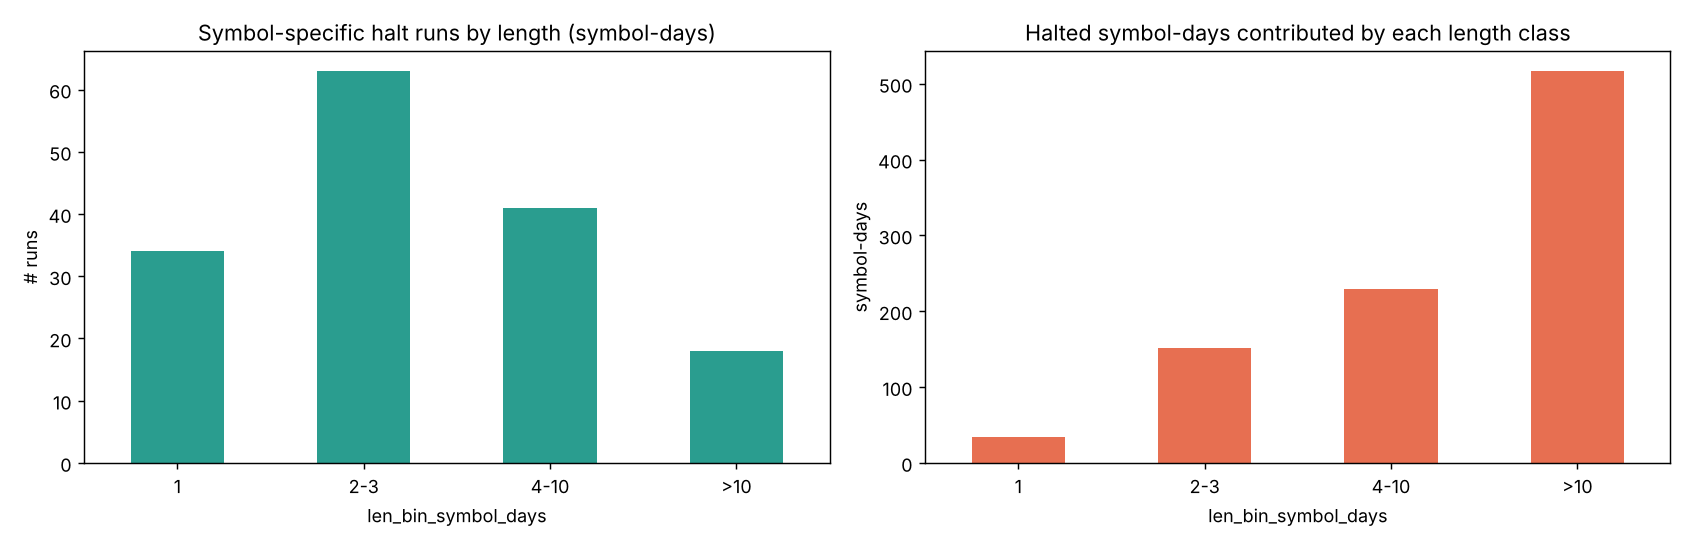

In [39]:
image("step3_halts_gaps/halt_run_lengths.png")

### step3_halts_gaps/halted_rows_by_month.png

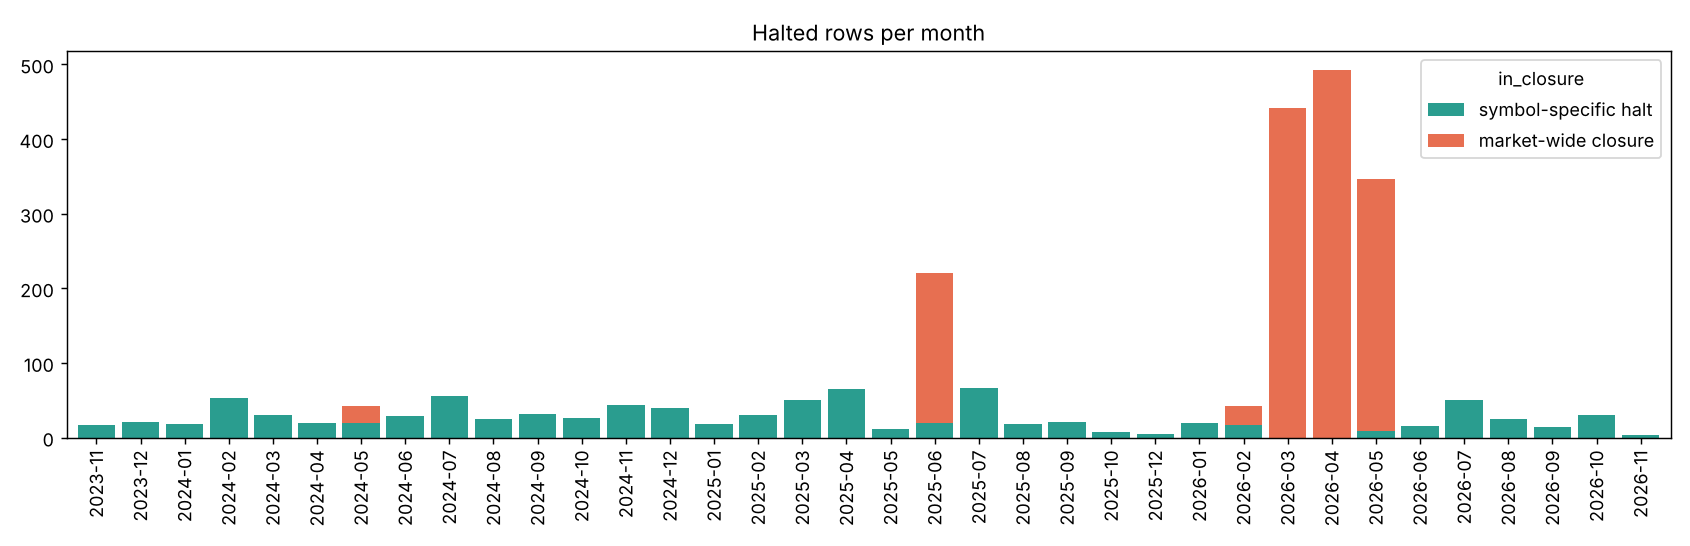

In [40]:
image("step3_halts_gaps/halted_rows_by_month.png")

## Step 4 - Adjustment events and volume adjustment

### step4_adjustments/summary.json

In [41]:
kv("step4_adjustments/summary.json")

step4_adjustments/summary.json


,value
n_events,69
classes,"{'PRICE_ONLY_DIVIDEND_LIKE': 31, 'AMBIGUOUS_SHARE_OR_DIVIDEND': 21, 'SHARE_I..."
share_events,34
delayed,"[بساما 2024-12-11, دزاگرس 2026-01-05, وبملت 2024-01-07]"
uncertain_records,174
price_anomaly_rows,2
pooled_slope_ratio_lt_09,1.0208
placebo_sd,"[0.5654541010542181, 0.6337709323619627, 0.6881093759830167, 0.7328561175341..."


### step4_adjustments/checks_summary.csv

In [42]:
table("step4_adjustments/checks_summary.csv")

step4_adjustments/checks_summary.csv  [18 rows x 5 cols]


,id,check,status,n_issues,detail
0,S4.01,event ratio == prev_final / previous record's final_price (69 events),PASS,0,69 events; max |recomputed - adj_ratio| = 4.9e-07
1,S4.02,adj_factor equals the cumulative backward product of the event ratios (every...,PASS,0,max relative deviation 8.6e-08
2,S4.03,events on halted rows: final_price already equals the NEW reference (prev_fi...,PASS,0,39/39 halted event rows carry the new reference as final_price (so halted ro...
3,S4.04,smallest event is larger than tick/rounding noise,PASS,0,min |1-ratio| = 0.0055; prices are integers so rounding error is ~1.5e-04
4,S4.05,"clusters of events (same symbol, <= 7 records apart)",WARN,3,"تاصيكو: 3 events, net ratio 0.9872; فملي: 2 events, net ratio 0.7132; وبملت:..."
5,S4.06,events with ratio > 1 (reference price UP on an adjustment day),WARN,2,تاصيكو 2026-09-16 ratio 1.983 -> REVERSAL_CLUSTER; هم تراز 2025-09-21 ratio ...
6,S4.07,adjusted return across each halt reproduces the exchange's reopen return (fi...,PASS,0,"213 halt runs; max |difference| = 0.0033, median 1.1e-08"
7,S4.08,adjusted return across the halt of event runs vs non-event halt runs of the ...,WARN,3,"64 testable events, 3 above the 95th percentile: E22(خساپا 2025-05-06 +59.6%..."
8,S4.09,pooled volume evidence: observed log volume step vs the exchange's log(1/rat...,INFO,33,"slope 1.02 (95% CI 0.78..1.24); ratio<0.3: slope 1.04 [0.84,1.29] n=8; 0.3<=..."
9,S4.10,final event classes,INFO,69,"{'PRICE_ONLY_DIVIDEND_LIKE': 31, 'AMBIGUOUS_SHARE_OR_DIVIDEND': 21, 'SHARE_I..."


### step4_adjustments/adj_event_final.csv

In [43]:
table("step4_adjustments/adj_event_final.csv")

step4_adjustments/adj_event_final.csv  [69 rows x 42 cols]


,event_id,symbol,date,date_jalali,jal_month,adj_ratio,inv_ratio,inv_ratio_is_round,in_dividend_season,on_halted_row,halt_symbol_days,halt_records,cluster_id,n_in_cluster,cluster_net_ratio,adj_ret_across_halt,ret_pctile_vs_nonevent,price_outlier,n_pre,exp_log,ex0,ex1,ex2,ex3,ex4,exv0,z0_vs_expected,z0_vs_none,best_j,support,power,amp_hat,volume_test,event_class,confidence,share_event,arrival,share_arrival_rank,share_step,action,external_check,step2_flags
0,E01,اخابر,2024-07-22,1403-05-01,5,0.95395,1.0483,False,True,False,3,3,1,1,0.95395,5.057e-07,0.083333,False,20,0.047147,-0.407,0.2475,-0.48655,0.25694,0.12523,-0.37032,-0.80316,-0.71978,3,0.058435,0.025369,4.0529,NOT_TESTABLE,PRICE_ONLY_DIVIDEND_LIKE,MEDIUM,False,-,0,1,KEEP,NaN,NaN
1,E02,اخابر,2025-04-06,1404-01-17,1,0.0625,16,True,False,True,22,22,2,1,0.0625,0.24906,0.83333,False,20,2.7726,2.8909,2.2362,2.265,2.5741,2.7219,0.24512,0.20922,5.1125,0,73.873,87.733,0.91524,CONFIRMED_IMMEDIATE,SHARE_INCREASE_IMMEDIATE,HIGH,True,event_day,0,16,KEEP,round 1/ratio (unit split or pure bonus issue): confirm terms,very_small_ratio
2,E03,اخابر,2025-07-09,1404-04-18,4,0.93631,1.068,False,True,True,4,4,3,1,0.93631,-0.027211,0.46154,False,20,0.065813,-1.0435,0.067847,-0.27837,-0.82825,-0.89735,-1.0608,-1.9618,-1.8454,4,-0.22307,0.049433,-13.635,NOT_TESTABLE,PRICE_ONLY_DIVIDEND_LIKE,MEDIUM,False,-,0,1,KEEP,NaN,NaN
3,E04,اخابر,2026-07-18,1405-04-27,4,0.93218,1.0728,False,True,True,5,5,4,1,0.93218,-0.029412,0.53846,False,20,0.07023,0.53681,0.17839,0.40037,0.23639,NaN,0.6034,0.82515,0.94935,0,0.43149,0.047306,4.8126,NOT_TESTABLE,PRICE_ONLY_DIVIDEND_LIKE,MEDIUM,False,-,0,1,KEEP,NaN,NaN
4,E05,اطلس,2023-11-21,1402-08-30,8,0.1,10,True,False,False,3,3,5,1,0.1,-0.0073905,0.11111,False,6,2.3026,2.5125,1.6174,1.9672,1.8305,2.5631,0.18625,0.37118,4.4433,0,50.552,60.51,0.9112,CONFIRMED_IMMEDIATE,SHARE_INCREASE_IMMEDIATE,HIGH,True,event_day,0,10,KEEP,round 1/ratio (unit split or pure bonus issue): confirm terms,very_small_ratio
5,E06,بساما,2024-07-23,1403-05-02,5,0.9744,1.0263,False,True,False,3,3,6,1,0.9744,-0.015762,0.19444,False,20,0.02593,0.32703,0.012731,0.13569,-0.13058,NaN,0.43228,0.5325,0.57836,0,0.050492,0.0064489,3.325,NOT_TESTABLE,PRICE_ONLY_DIVIDEND_LIKE,MEDIUM,False,-,0,1,KEEP,NaN,NaN
6,E07,بساما,2024-12-11,1403-09-21,9,0.41637,2.4017,False,False,True,6,6,7,1,0.41637,0.011863,0.38462,False,20,0.87617,0.10939,0.93255,1.1957,1.658,0.94845,-0.78954,-1.356,0.19346,1,10.571,8.7614,1.351,CONFIRMED_DELAYED,SHARE_INCREASE_DELAYED,HIGH,True,delayed,13,2.4017,KEEP,confirm registration date of the new shares,NaN
7,E08,بساما,2026-07-27,1405-05-05,5,0.9945,1.0055,False,True,False,4,4,8,1,0.9945,0.021018,0.46154,False,20,0.0055162,0.74175,0.98588,0.59034,1.2086,NaN,0.74834,1.302,1.3118,0,0.090962,0.00029184,159.83,NOT_TESTABLE,PRICE_ONLY_DIVIDEND_LIKE,MEDIUM,False,-,0,1,KEEP,NaN,NaN
8,E09,تابان,2026-09-23,1405-07-01,7,0.96835,1.0327,False,False,False,2,2,9,1,0.96835,0.10236,0.94444,False,15,0.032167,1.2011,0.53431,NaN,NaN,NaN,1.4977,2.0672,2.1241,0,0.32144,0.0058121,26.975,NOT_TESTABLE,PRICE_ONLY_DIVIDEND_LIKE,MEDIUM,False,-,0,1,KEEP,NaN,big_move_on_event_day
9,E10,تاصيكو,2024-08-24,1403-06-03,6,0.8956,1.1166,False,False,True,4,4,10,1,0.8956,0.01227,0.38462,False,20,0.11026,-0.44624,0.1154,-0.92897,-1.4267,-1.382,-0.5098,-0.98416,-0.78918,4,-0.57734,0.13874,-12.534,NOT_TESTABLE,AMBIGUOUS_SHARE_OR_DIVIDEND,LOW,True,event_day,0,1.1166,KEEP,NaN,NaN


### step4_adjustments/adj_events_corrected.csv

In [44]:
table("step4_adjustments/adj_events_corrected.csv")

step4_adjustments/adj_events_corrected.csv  [66 rows x 3 cols]


,symbol,date,ratio
0,اخابر,2024-07-22,0.95395
1,اخابر,2025-04-06,0.0625
2,اخابر,2025-07-09,0.93631
3,اخابر,2026-07-18,0.93218
4,اطلس,2023-11-21,0.1
5,بساما,2024-07-23,0.9744
6,بساما,2024-12-11,0.41637
7,بساما,2026-07-27,0.9945
8,تابان,2026-09-23,0.96835
9,تاصيكو,2024-08-24,0.8956


### step4_adjustments/adj_events_corrected_net_events.csv

In [45]:
table("step4_adjustments/adj_events_corrected_net_events.csv")

step4_adjustments/adj_events_corrected_net_events.csv  [1 rows x 5 cols]


,symbol,date,pos,ratio,source
0,تاصيكو,2026-09-16,681,0.98719,net of cluster تاصيكو


### step4_adjustments/adjusted_series.csv

In [46]:
table("step4_adjustments/adjusted_series.csv")

step4_adjustments/adjusted_series.csv  [17368 rows x 17 cols]

,symbol,date,is_halted,volume,value,adj_factor,adj_factor_corrected,adj_final_corrected,price_anomaly,share_factor,adj_volume,volume_adj_uncertain,adj_volume_m1_by_adj_factor,ind_buy_vol_adj,ind_sell_vol_adj,corp_buy_vol_adj,corp_sell_vol_adj
0,اخابر,2023-11-08,False,2.5462e+07,2.5242e+11,0.052038,0.052038,515.7,False,16,4.0739e+08,False,4.893e+08,3.6042e+08,2.3858e+08,4.6969e+07,1.6882e+08
1,اخابر,2023-11-11,False,2.0052e+07,1.9515e+11,0.052038,0.052038,506.33,False,16,3.2083e+08,False,3.8533e+08,2.6588e+08,2.6954e+08,5.4948e+07,5.1284e+07
2,اخابر,2023-11-12,False,1.7107e+07,1.6186e+11,0.052038,0.052038,492.28,False,16,2.7372e+08,False,3.2875e+08,2.5372e+08,2.4939e+08,2.0002e+07,2.4325e+07
3,اخابر,2023-11-13,False,1.7472e+07,1.6615e+11,0.052038,0.052038,494.88,False,16,2.7956e+08,False,3.3576e+08,2.4836e+08,2.1338e+08,3.12e+07,6.6177e+07
4,اخابر,2023-11-14,False,2.3769e+07,2.208e+11,0.052038,0.052038,483.43,False,16,3.803e+08,False,4.5675e+08,2.6722e+08,3.2817e+08,1.1308e+08,5.2132e+07
5,اخابر,2023-11-15,False,2.7602e+07,2.6183e+11,0.052038,0.052038,493.84,False,16,4.4163e+08,False,5.3042e+08,3.639e+08,2.886e+08,7.7734e+07,1.5303e+08
6,اخابر,2023-11-18,False,1.5261e+07,1.44e+11,0.052038,0.052038,491.24,False,16,2.4418e+08,False,2.9327e+08,2.1902e+08,1.6207e+08,2.5165e+07,8.211e+07
7,اخابر,2023-11-19,False,1.3663e+07,1.2662e+11,0.052038,0.052038,482.39,False,16,2.1861e+08,False,2.6257e+08,2.0727e+08,1.6009e+08,1.134e+07,5.8523e+07
8,اخابر,2023-11-20,False,1.4397e+07,1.3085e+11,0.052038,0.052038,473.03,False,16,2.3035e+08,False,2.7666e+08,1.9323e+08,1.9546e+08,3.7125e+07,3.4888e+07
9,اخابر,2023-11-21,False,3.1712e+07,2.965e+11,0.052038,0.052038,486.56,False,16,5.074e+08,False,6.0941e+08,4.8955e+08,2.5462e+08,1.7842e+07,2.5277e+08


### step4_adjustments/events_to_verify_externally.csv

In [47]:
table("step4_adjustments/events_to_verify_externally.csv")

step4_adjustments/events_to_verify_externally.csv  [24 rows x 7 cols]


,event_id,symbol,date,adj_ratio,event_class,confidence,external_check
0,E02,اخابر,2025-04-06,0.0625,SHARE_INCREASE_IMMEDIATE,HIGH,round 1/ratio (unit split or pure bonus issue): confirm terms
1,E05,اطلس,2023-11-21,0.1,SHARE_INCREASE_IMMEDIATE,HIGH,round 1/ratio (unit split or pure bonus issue): confirm terms
2,E07,بساما,2024-12-11,0.41637,SHARE_INCREASE_DELAYED,HIGH,confirm registration date of the new shares
3,E12,تاصيكو,2026-03-30,0.72535,AMBIGUOUS_SHARE_OR_DIVIDEND,LOW,large ratio but volume cannot confirm: capital increase or big dividend?
4,E13,تاصيكو,2026-09-14,0.51602,REVERSAL_CLUSTER,HIGH,data artefact: confirm the reference price on the exchange page
5,E14,تاصيكو,2026-09-15,0.96494,REVERSAL_CLUSTER,HIGH,data artefact: confirm the reference price on the exchange page
6,E15,تاصيكو,2026-09-16,1.9826,REVERSAL_CLUSTER,HIGH,data artefact: confirm the reference price on the exchange page
7,E21,خبهمن,2026-07-26,0.87212,AMBIGUOUS_SHARE_OR_DIVIDEND,LOW,falls in the dividend season (Jalali months 4-5): dividend is a serious alte...
8,E22,خساپا,2025-05-06,0.1206,SHARE_INCREASE_IMMEDIATE,HIGH,halt-to-reopen return is an outlier for its halt length
9,E23,خودرو,2025-04-22,0.11763,SHARE_INCREASE_IMMEDIATE,HIGH,halt-to-reopen return is an outlier for its halt length


### step4_adjustments/halt_run_returns.csv

In [48]:
table("step4_adjustments/halt_run_returns.csv")

step4_adjustments/halt_run_returns.csv  [213 rows x 10 cols]


,symbol,run_start,n_records,n_symbol_days,has_event,ret_across,reopen_ret,len_bin,abs_ret,pctile_vs_nonevent
0,اخابر,2023-12-10,1,1,False,-0.0087489,-0.0087489,1,0.0087489,NaN
1,اخابر,2023-12-30,2,2,False,0.013525,0.013525,2-3,0.013525,NaN
2,اخابر,2024-05-20,1,0,False,-0.0086634,-0.0086634,0,0.0086634,NaN
3,اخابر,2024-07-17,3,3,True,5.057e-07,0,2-3,5.057e-07,0.083333
4,اخابر,2024-07-29,4,4,False,0,0,4-10,0,NaN
5,اخابر,2024-12-31,1,1,False,0.023605,0.023605,1,0.023605,NaN
6,اخابر,2025-02-16,2,2,False,-0.024533,-0.024533,2-3,0.024533,NaN
7,اخابر,2025-03-04,2,2,False,-0.012168,-0.012168,2-3,0.012168,NaN
8,اخابر,2025-03-17,22,22,True,0.24906,0.24906,>10,0.24906,0.83333
9,اخابر,2025-06-15,8,0,False,-0.020771,-0.020772,0,0.020771,NaN


### step4_adjustments/volume_method_comparison.csv

In [49]:
table("step4_adjustments/volume_method_comparison.csv")

step4_adjustments/volume_method_comparison.csv  [20 rows x 6 cols]


,group,method,n_obs,mean_residual_log,rmse_log,placebo_noise_sd
0,confirmed share increases,M0 raw volume,59,1.5112,1.7059,0.67222
1,confirmed share increases,M1 volume / adj_factor,59,-0.052188,0.55344,0.67222
2,confirmed share increases,M2 volume x 1/ratio if ratio<0.9,59,-0.052188,0.55344,0.67222
3,confirmed share increases,M2t timing-aware share factor (chosen),59,8.7656e-05,0.51927,0.67222
4,confirmed share increases,M3 traded value (Rial),59,0.06444,0.64026,0.67222
5,probable/ambiguous (ratio<0.9),M0 raw volume,101,0.29503,0.66919,0.67222
6,probable/ambiguous (ratio<0.9),M1 volume / adj_factor,101,0.048371,0.60149,0.67222
7,probable/ambiguous (ratio<0.9),M2 volume x 1/ratio if ratio<0.9,101,0.048371,0.60149,0.67222
8,probable/ambiguous (ratio<0.9),M2t timing-aware share factor (chosen),101,0.048371,0.60149,0.67222
9,probable/ambiguous (ratio<0.9),M3 traded value (Rial),101,0.0885,0.63658,0.67222


### step4_adjustments/volume_paths.csv

In [50]:
table("step4_adjustments/volume_paths.csv")

step4_adjustments/volume_paths.csv  [69 rows x 33 cols]


,event_id,symbol,date,lv0,mv0,ex0,lval0,mu0,exv0,lv1,mv1,ex1,lval1,mu1,exv1,lv2,mv2,ex2,lval2,mu2,exv2,lv3,mv3,ex3,lval3,mu3,exv3,lv4,mv4,ex4,lval4,mu4,exv4
0,E01,اخابر,2024-07-22,-0.60779,-0.20079,-0.407,-0.60636,-0.23604,-0.37032,0.093271,-0.15423,0.2475,0.15956,-0.31598,0.47554,-0.82082,-0.33427,-0.48655,-0.82315,-0.33133,-0.49182,0.67461,0.41768,0.25694,0.62164,0.41525,0.20639,1.588,1.4628,0.12523,1.8608,1.5934,0.26737
1,E02,اخابر,2025-04-06,3.5481,0.65725,2.8909,1.0281,0.78297,0.24512,2.5463,0.31007,2.2362,0.010666,0.4846,-0.47394,2.118,-0.14696,2.265,-0.70973,-0.074375,-0.63535,2.4112,-0.16285,2.5741,-0.6681,-0.24436,-0.42375,2.4632,-0.25871,2.7219,-0.5301,-0.53011,3.2538e-06
2,E03,اخابر,2025-07-09,-0.72435,0.31914,-1.0435,-1.0094,0.051442,-1.0608,-0.10419,-0.17203,0.067847,-0.66558,-0.63441,-0.031164,-0.20889,0.06948,-0.27837,-0.74191,-0.11332,-0.62859,-0.16718,0.66107,-0.82825,-0.50593,0.80326,-1.3092,-0.72965,0.1677,-0.89735,-1.0648,-0.0038186,-1.061
3,E04,اخابر,2026-07-18,0.52561,-0.011203,0.53681,0.61888,0.01548,0.6034,0.36188,0.18348,0.17839,0.78546,0.48766,0.29781,0.26378,-0.13659,0.40037,0.7058,0.40638,0.29943,-0.21379,-0.45018,0.23639,0.27957,0.15502,0.12455,NaN,NaN,NaN,NaN,NaN,NaN
4,E05,اطلس,2023-11-21,2.7664,0.25398,2.5125,0.50588,0.31963,0.18625,1.6952,0.077833,1.6174,-0.54561,0.16513,-0.71074,1.8999,-0.067272,1.9672,-0.38288,-0.080587,-0.3023,2.1662,0.33574,1.8305,-0.08487,0.40573,-0.4906,2.6566,0.093547,2.5631,0.45917,0.16165,0.29752
5,E06,بساما,2024-07-23,0.069383,-0.25765,0.32703,0.058723,-0.37356,0.43228,-0.012033,-0.024764,0.012731,0.043817,-0.066147,0.10996,-0.27991,-0.4156,0.13569,-0.23667,-0.47685,0.24018,0.4147,0.54529,-0.13058,0.51607,0.48852,0.027546,NaN,1.6128,NaN,NaN,1.8403,NaN
6,E07,بساما,2024-12-11,0.16372,0.054327,0.10939,-0.58861,0.20093,-0.78954,0.49358,-0.43897,0.93255,-0.15127,-0.42045,0.26918,0.83959,-0.35613,1.1957,0.33152,-0.077441,0.40896,1.0061,-0.65196,1.658,0.58248,-0.32337,0.90585,0.88359,-0.064862,0.94845,0.45483,0.3284,0.12643
7,E08,بساما,2026-07-27,0.85714,0.1154,0.74175,1.0576,0.30927,0.74834,1.0306,0.044756,0.98588,1.4331,0.44934,0.98376,0.47327,-0.11707,0.59034,0.92767,0.42251,0.50516,0.70683,-0.50178,1.2086,0.84348,-0.045332,0.88882,NaN,NaN,NaN,NaN,NaN,NaN
8,E09,تابان,2026-09-23,0.93459,-0.2665,1.2011,1.3759,-0.12179,1.4977,-0.10187,-0.63618,0.53431,0.2396,-0.4268,0.6664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,E10,تاصيكو,2024-08-24,-0.31296,0.13328,-0.44624,-0.36097,0.14884,-0.5098,-0.035057,-0.15046,0.1154,-0.066843,-0.12913,0.062289,-0.20161,0.72736,-0.92897,-0.15211,0.73939,-0.8915,0.20968,1.6364,-1.4267,0.38546,1.8368,-1.4514,0.036111,1.4181,-1.382,0.33088,1.793,-1.4621


### step4_adjustments/volume_placebo_noise.csv

In [51]:
table("step4_adjustments/volume_placebo_noise.csv")

step4_adjustments/volume_placebo_noise.csv  [5 rows x 5 cols]


,window,n_placebo,sd_excess_log_volume,mean_excess_log_volume,sd_excess_log_value
0,+3..+23,842,0.56545,-0.011412,0.57785
1,+23..+43,842,0.63377,0.0033956,0.65492
2,+43..+63,842,0.68811,-0.024672,0.71774
3,+63..+83,842,0.73286,-0.036415,0.76317
4,+83..+103,842,0.74089,-0.032485,0.76001


### step4_adjustments/volume_pooled_slope.csv

In [52]:
table("step4_adjustments/volume_pooled_slope.csv")

step4_adjustments/volume_pooled_slope.csv  [10 rows x 8 cols]


,group,window,n,mean_expected_log,mean_observed_excess,slope_through_origin,ci95_low,ci95_high
0,ratio<0.3,w0 (+3..+23),8,1.9823,2.1259,1.0449,0.84023,1.2858
1,ratio<0.3,mean of w0..w4,8,1.9823,1.8777,0.93051,0.81826,1.0625
2,0.3<=ratio<0.9,w0 (+3..+23),25,0.31722,0.25192,0.80015,0.32156,1.4493
3,0.3<=ratio<0.9,mean of w0..w4,25,0.31722,0.36014,1.036,0.80607,1.2922
4,ratio<0.9 (all),w0 (+3..+23),33,0.72086,0.70622,1.0208,0.78456,1.2442
5,ratio<0.9 (all),mean of w0..w4,33,0.72086,0.72804,0.94089,0.83766,1.0686
6,ratio>=0.9,w0 (+3..+23),28,0.048318,-0.056027,-1.6911,-4.9571,1.9549
7,ratio>=0.9,mean of w0..w4,28,0.048318,-0.029052,-0.8128,-4.1872,2.8467
8,ambiguous/probable only (biased low),w0 (+3..+23),21,0.24926,0.1627,0.6945,0.12656,1.3187
9,ambiguous/probable only (biased low),mean of w0..w4,21,0.24926,0.28831,0.98212,0.57712,1.532


### step4_adjustments/price_side_check.png

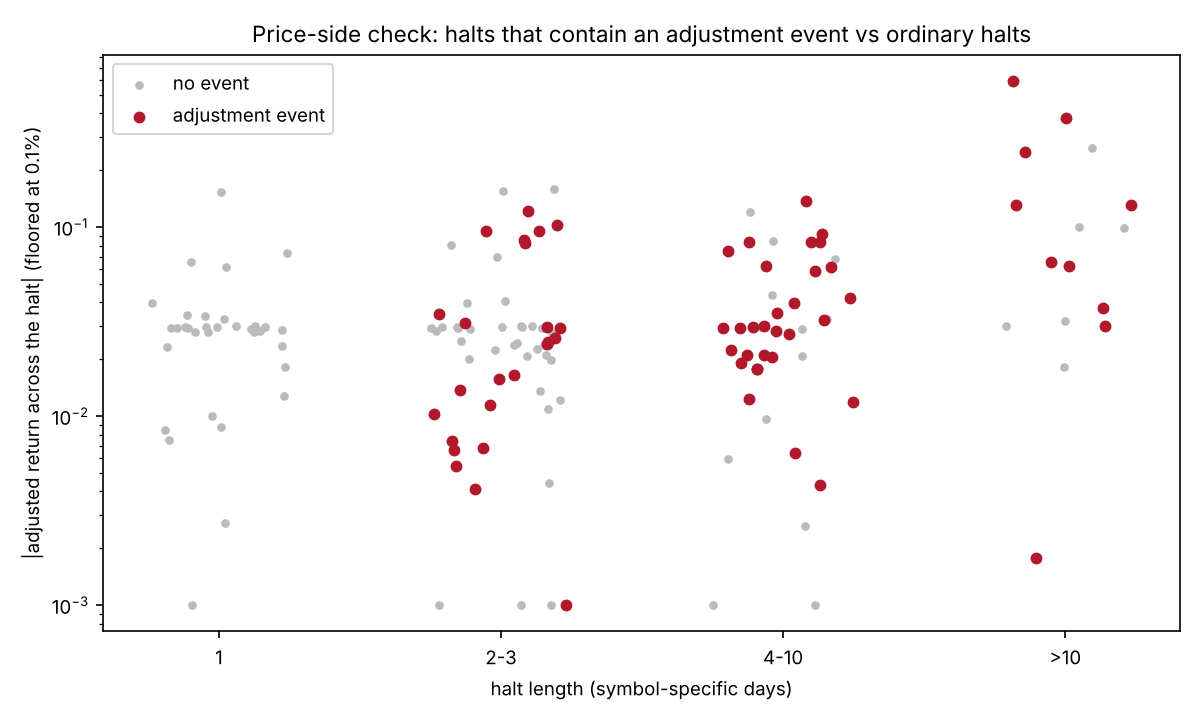

In [53]:
image("step4_adjustments/price_side_check.png")

### step4_adjustments/volume_step_vs_expected.png

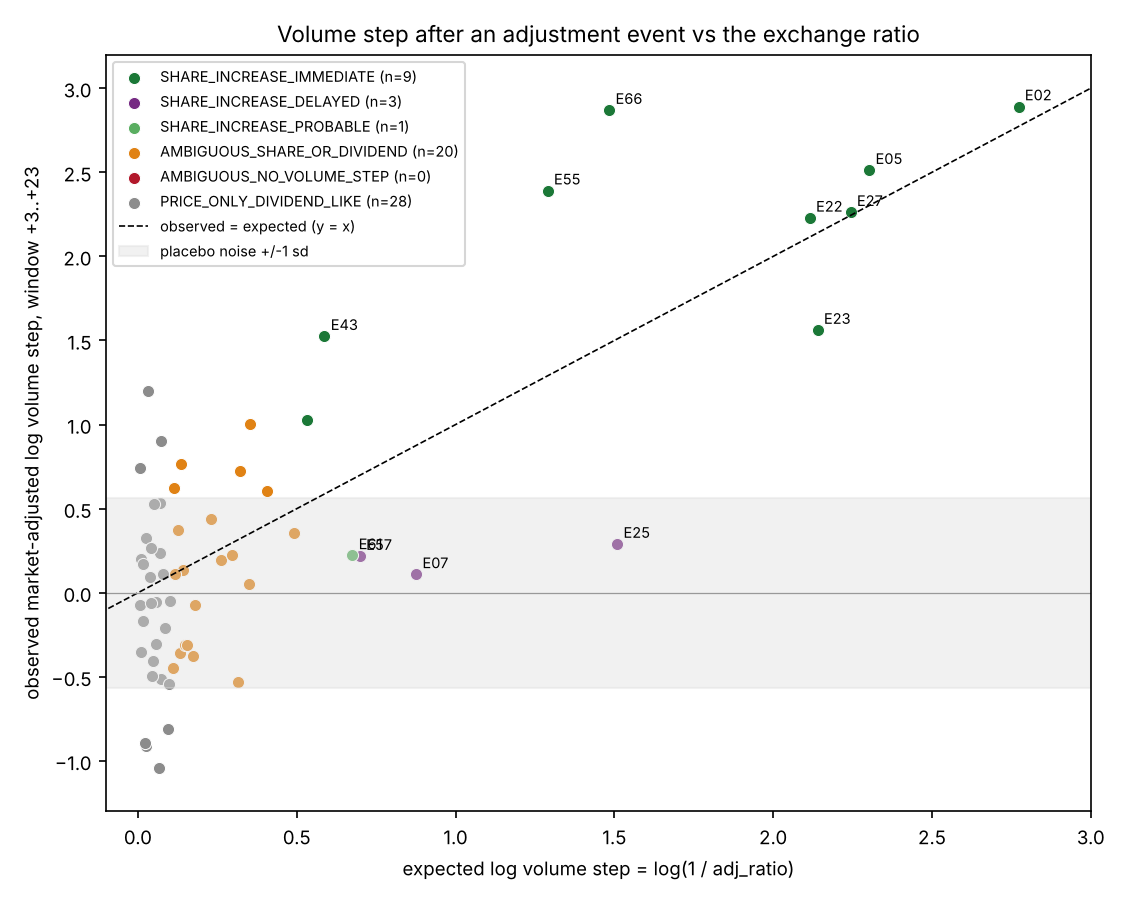

In [54]:
image("step4_adjustments/volume_step_vs_expected.png")

### step4_adjustments/volume_timing_paths.png

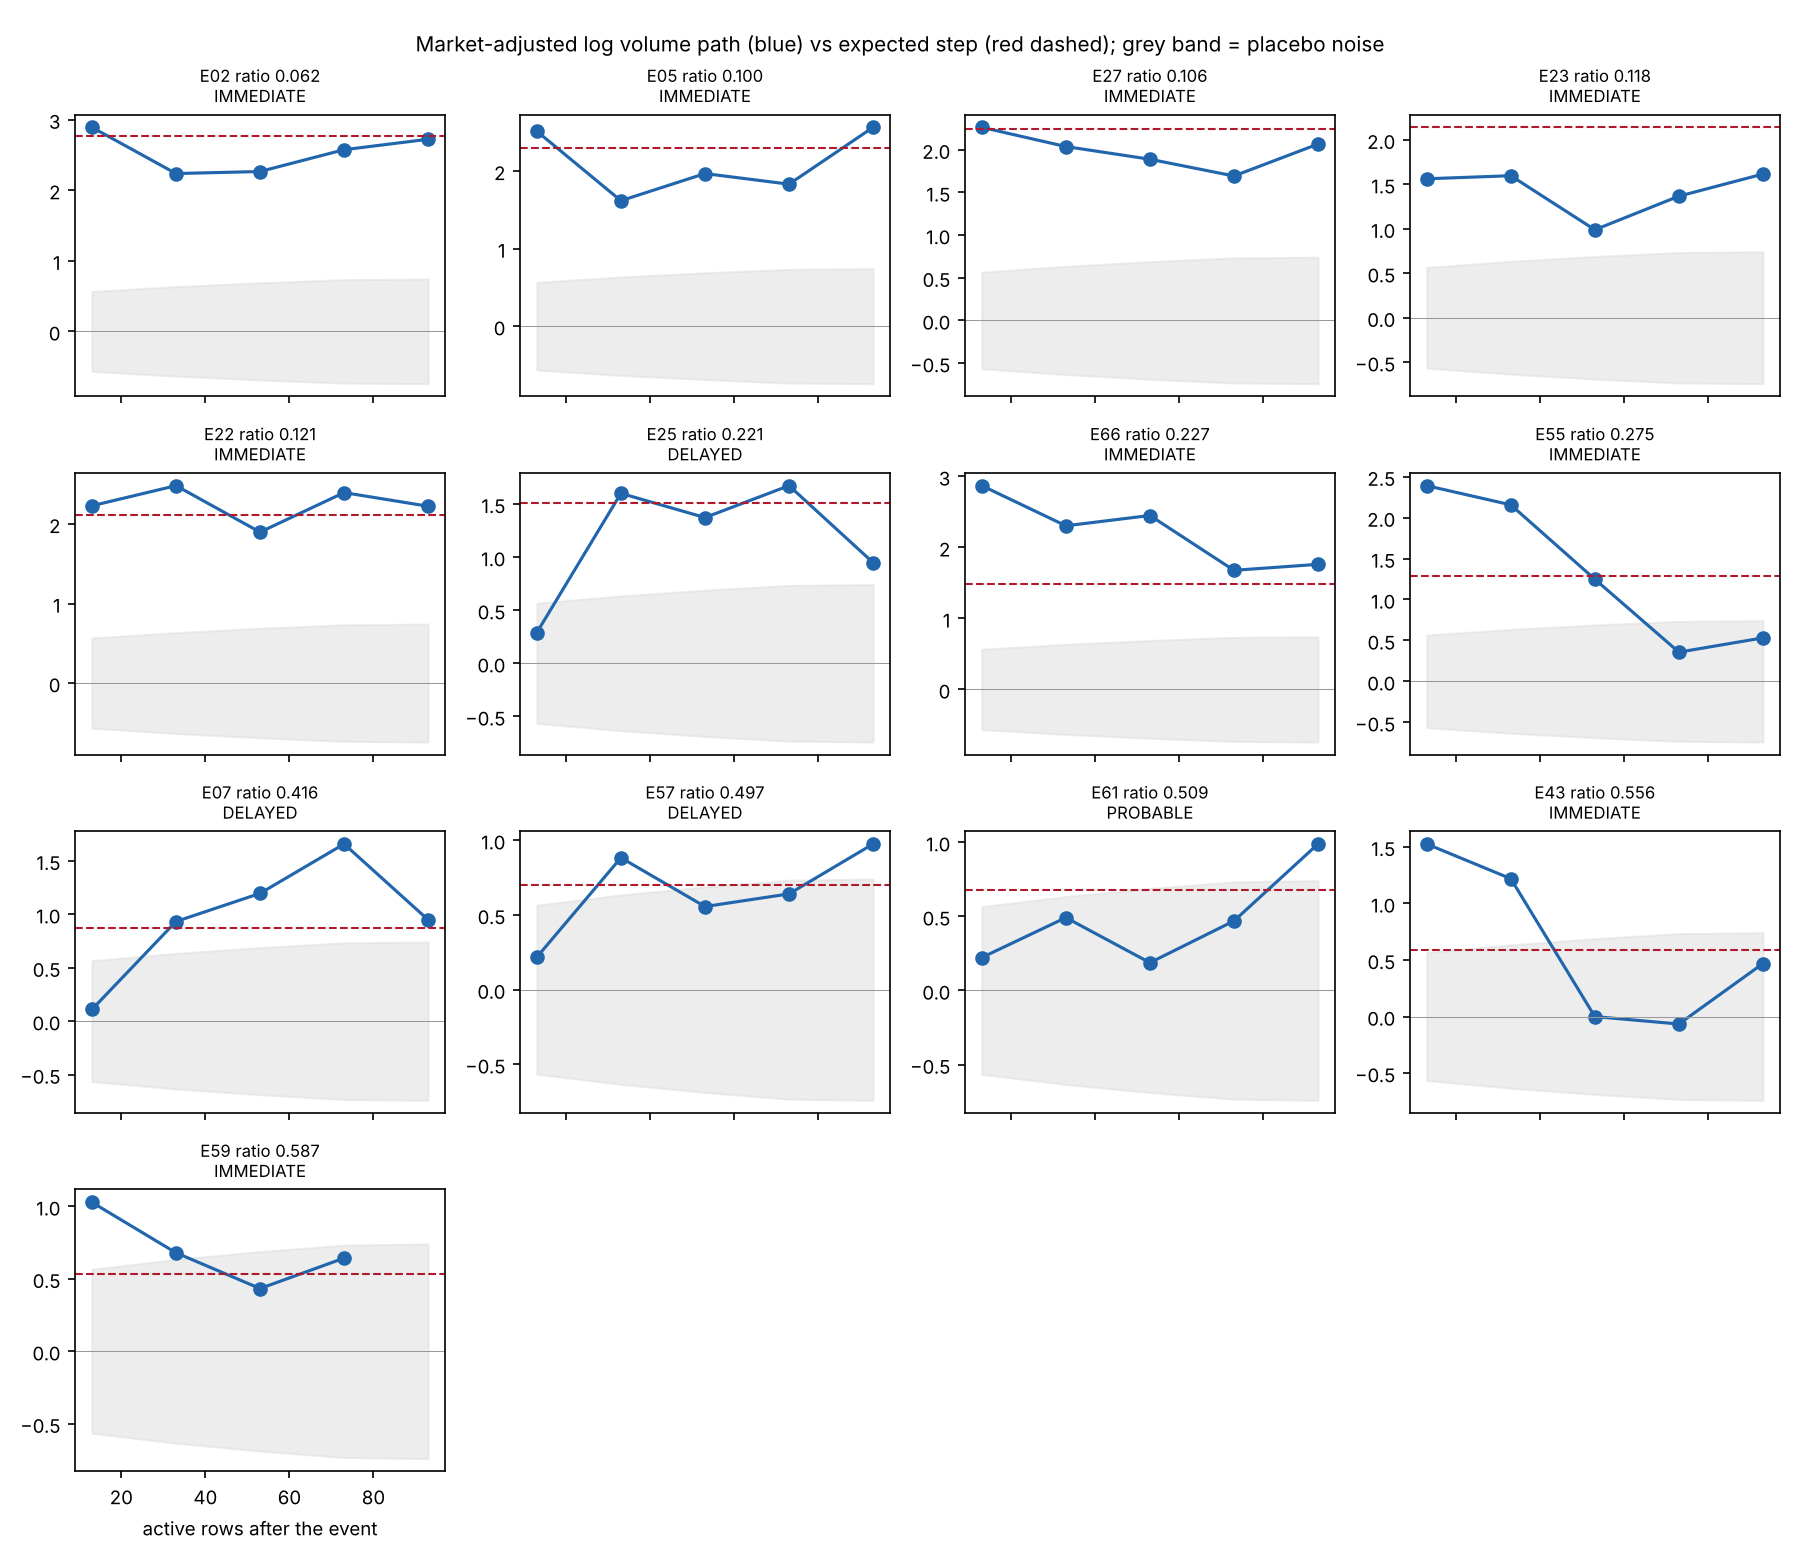

In [55]:
image("step4_adjustments/volume_timing_paths.png")

## Step 5 - Symbol profile

### step5_profile/summary.json

In [56]:
kv("step5_profile/summary.json")

step5_profile/summary.json


,value
symbols,27
tiers,"{'T1_high': 9, 'T3_low': 9, 'T2_mid': 8, 'short_history': 1}"
INFO,5
PASS,3
WARN,1


### step5_profile/checks_summary.csv

In [57]:
table("step5_profile/checks_summary.csv")

step5_profile/checks_summary.csv  [9 rows x 5 cols]


,id,check,status,n_issues,detail
0,S5.01,one profile row per symbol,PASS,0,27 symbols
1,S5.02,symbol_halt_days equals the step 1 symbol-specific halt count,PASS,0,NaN
2,S5.03,active_days + halted records = records (closure days are halted records),INFO,0,"difference = market-closure rows, which are excluded from tradable_days"
3,S5.04,adjusted prices positive and finite,PASS,0,NaN
4,S5.05,"liquidity range (median daily traded value, symbols with >= 200 active days)",INFO,NaN,most liquid اهرم: 3984.0 bn Rial; least liquid طعام: 8.91 bn Rial; ratio 447...
5,S5.06,liquidity tiers (terciles among symbols with enough history),INFO,NaN,T1_high=9; T2_mid=8; T3_low=9; short_history=1
6,S5.07,symbols with fewer than 200 active days,WARN,1,تابان=47
7,S5.08,retail share of buy value across symbols,INFO,NaN,"min 0.31, median 0.66, max 0.91"
8,S5.09,adjusted total return over each symbol's active period,INFO,NaN,median +273.2%; best فزر +1673.9%; worst فرابورس +29.0%


### step5_profile/liquidity_tiers.csv

In [58]:
table("step5_profile/liquidity_tiers.csv")

step5_profile/liquidity_tiers.csv  [4 rows x 5 cols]


,liquidity_tier,n_symbols,min_median_value,max_median_value,symbols
0,T1_high,9,6.4621e+11,3.984e+12,اهرم وبملت موج خودرو فملي توان شپنا فزر شستا
1,T2_mid,8,2.2545e+11,6.155e+11,خساپا وتجارت ذوب وبصادر اطلس دزاگرس اخابر دارونو
2,T3_low,9,8.9133e+09,2.2283e+11,جوانه كوچك تاپيكو خبهمن فرابورس هم تراز تاصيكو كاريس بساما طعام
3,short_history,1,5.8922e+12,5.8922e+12,تابان


### step5_profile/symbol_profile.csv

In [59]:
table("step5_profile/symbol_profile.csv")

step5_profile/symbol_profile.csv  [27 rows x 35 cols]


,symbol,ins_code,first_record,first_trade_date,last_date,n_records,tradable_days,active_days,symbol_halt_days,no_record_days,symbol_halt_pct,active_share,longest_active_streak,n_adj_events_raw,n_adj_events_valid,first_adj_price,last_adj_price,adj_total_return,adj_log_return,median_final_price_raw,last_final_price_raw,median_value,mean_value,p10_value,value_cv,median_trade_count,mean_trade_count,median_avg_trade_value,retail_buy_value_share,retail_sell_value_share,median_retail_buyers,median_corp_buyers,median_value_billion_rial,liquidity_rank,liquidity_tier
0,تابان,30714151942396396,2026-08-02,2026-08-31,2026-11-07,67,67,47,20,0,29.85,0.7015,32,1,1,"12,395","23,970",0.93387,0.65953,"22,410","23,970",5.8922e+12,1.0865e+13,1.2763e+12,1.3473,"38,303",1.006e+05,1.5794e+08,0.77461,0.65492,"4,444",43,"5,892.2",1,short_history
1,اهرم,17914401175772326,2023-11-08,2023-11-08,2026-11-07,718,659,659,0,0,0,1,659,0,0,"18,810","78,124",3.1533,1.4239,"23,960","78,124",3.984e+12,6.1488e+12,7.4174e+11,0.98516,"10,908","11,673",4.4263e+08,0.85157,0.86396,"2,532",27,"3,984",2,T1_high
2,وبملت,778253364357513,2023-11-08,2023-11-08,2026-11-07,718,659,629,30,0,4.55,0.9545,179,7,7,434.01,"1,460",2.364,1.2131,"2,104","1,460",2.3006e+12,4.2547e+12,3.6326e+11,1.2782,"12,318","18,460",1.7849e+08,0.65097,0.69623,"2,584",23,"2,300.6",3,T1_high
3,موج,67141987086032267,2023-11-08,2023-11-25,2026-11-07,717,659,647,11,1,1.67,0.9818,575,0,0,"10,180",1.0471e+05,9.2861,2.3308,"21,474",1.0471e+05,1.568e+12,3.8971e+12,1.3141e+11,1.297,"4,235","6,088.9",4.6489e+08,0.91427,0.90713,"1,016",10,"1,568",4,T1_high
4,خودرو,65883838195688438,2023-11-08,2023-11-08,2026-11-07,718,659,582,77,0,11.68,0.8832,93,1,1,309.14,674,1.1803,0.77945,"2,306",674,1.2225e+12,2.1705e+12,2.5721e+11,1.1949,"9,476.5","15,400",1.0938e+08,0.71069,0.76452,"1,907",18,"1,222.5",5,T1_high
5,فملي,35425587644337450,2023-11-08,2023-11-08,2026-11-07,718,659,611,48,0,7.28,0.9272,185,6,6,"2,608","29,670",10.376,2.4315,"7,520","29,670",1.0355e+12,3.4572e+12,3.2794e+11,1.7169,"5,144","11,643",1.9138e+08,0.60661,0.59876,"1,547",16,"1,035.5",6,T1_high
6,توان,41927452991671109,2023-11-08,2023-11-08,2026-11-07,717,659,658,0,1,0,0.9985,575,0,0,"17,204","75,843",3.4085,1.4835,"22,206","75,843",9.1422e+11,1.6774e+12,1.968e+11,1.1316,"3,565","4,606.2",2.9491e+08,0.8154,0.81993,944.5,8,914.22,7,T1_high
7,شپنا,7745894403636165,2023-11-08,2023-11-08,2026-11-07,718,659,620,39,0,5.92,0.9408,177,6,6,"2,302.7","12,010",4.2156,1.6517,"5,210","12,010",7.8033e+11,2.2268e+12,2.2142e+11,1.8156,"4,898.5","8,123.8",1.6944e+08,0.61139,0.63389,"1,426.5",14,780.33,8,T1_high
8,فزر,8175784894140974,2023-11-08,2023-11-08,2026-11-07,717,659,627,31,1,4.7,0.9514,133,4,4,"18,620",3.303e+05,16.739,2.8758,"52,000",3.303e+05,7.7335e+11,2.034e+12,1.6976e+11,1.8496,"5,135","8,887",1.4972e+08,0.86052,0.79459,"1,925",9,773.35,9,T1_high
9,شستا,2400322364771558,2023-11-08,2023-11-08,2026-11-07,718,659,651,8,0,1.21,0.9879,232,3,3,817.27,"3,350",3.099,1.4107,"1,298","3,350",6.4621e+11,1.5514e+12,2.2515e+11,1.4141,"5,966","7,868.4",1.1655e+08,0.50493,0.60041,"1,130",19,646.21,10,T1_high


### step5_profile/active_share_vs_liquidity.png

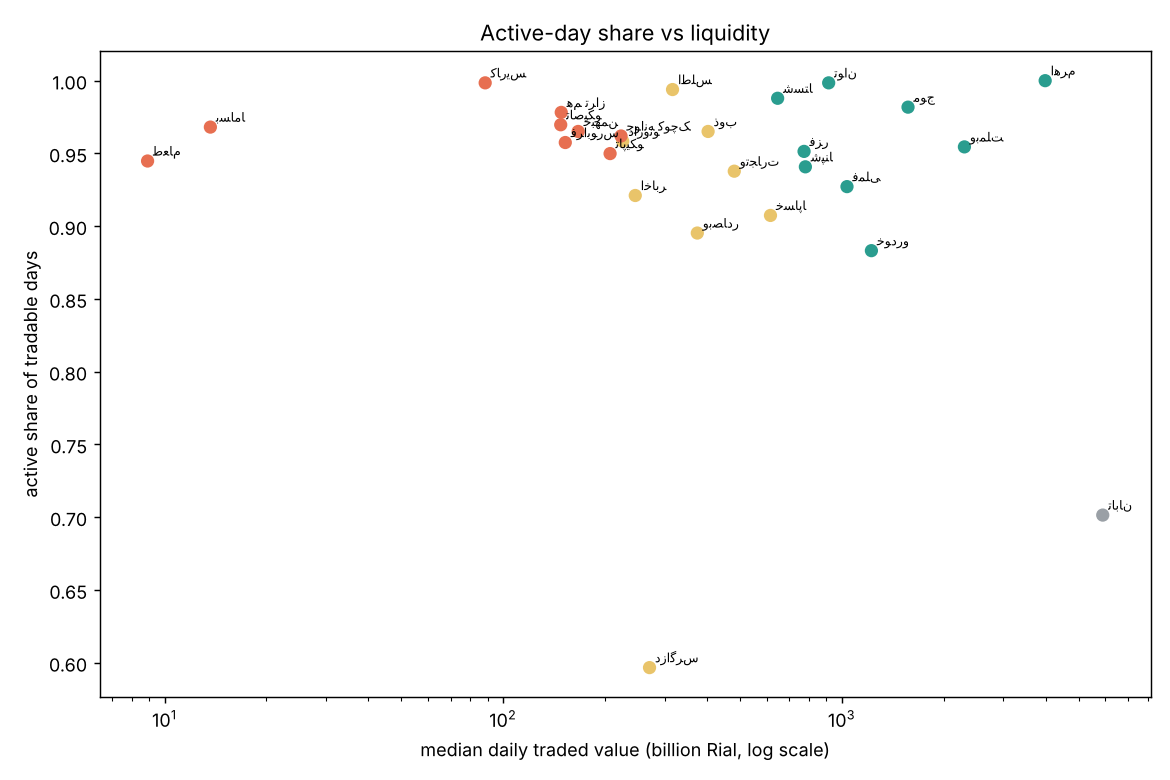

In [60]:
image("step5_profile/active_share_vs_liquidity.png")

### step5_profile/median_daily_value.png

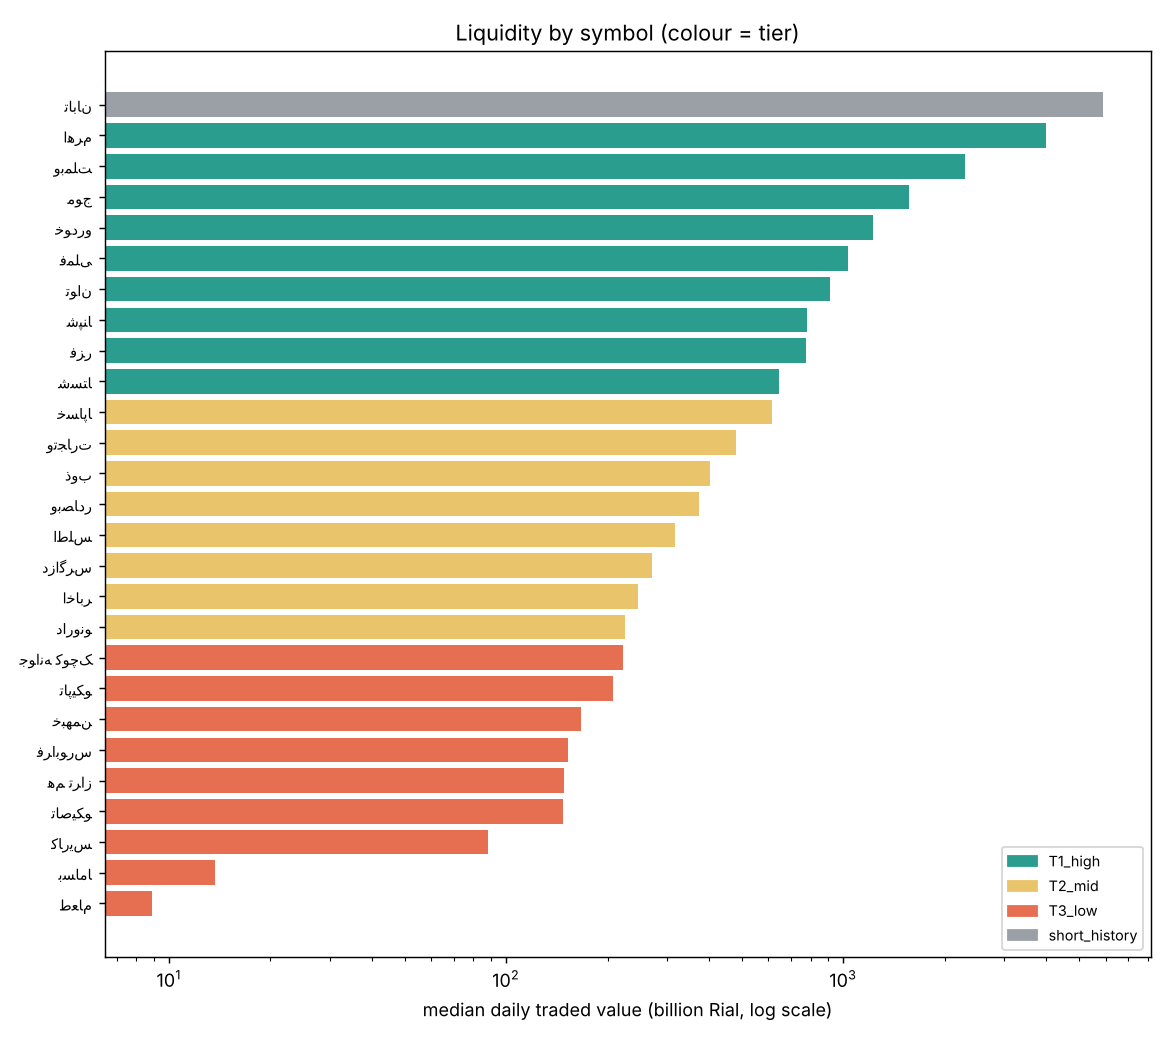

In [61]:
image("step5_profile/median_daily_value.png")

### step5_profile/raw_vs_adjusted_price.png

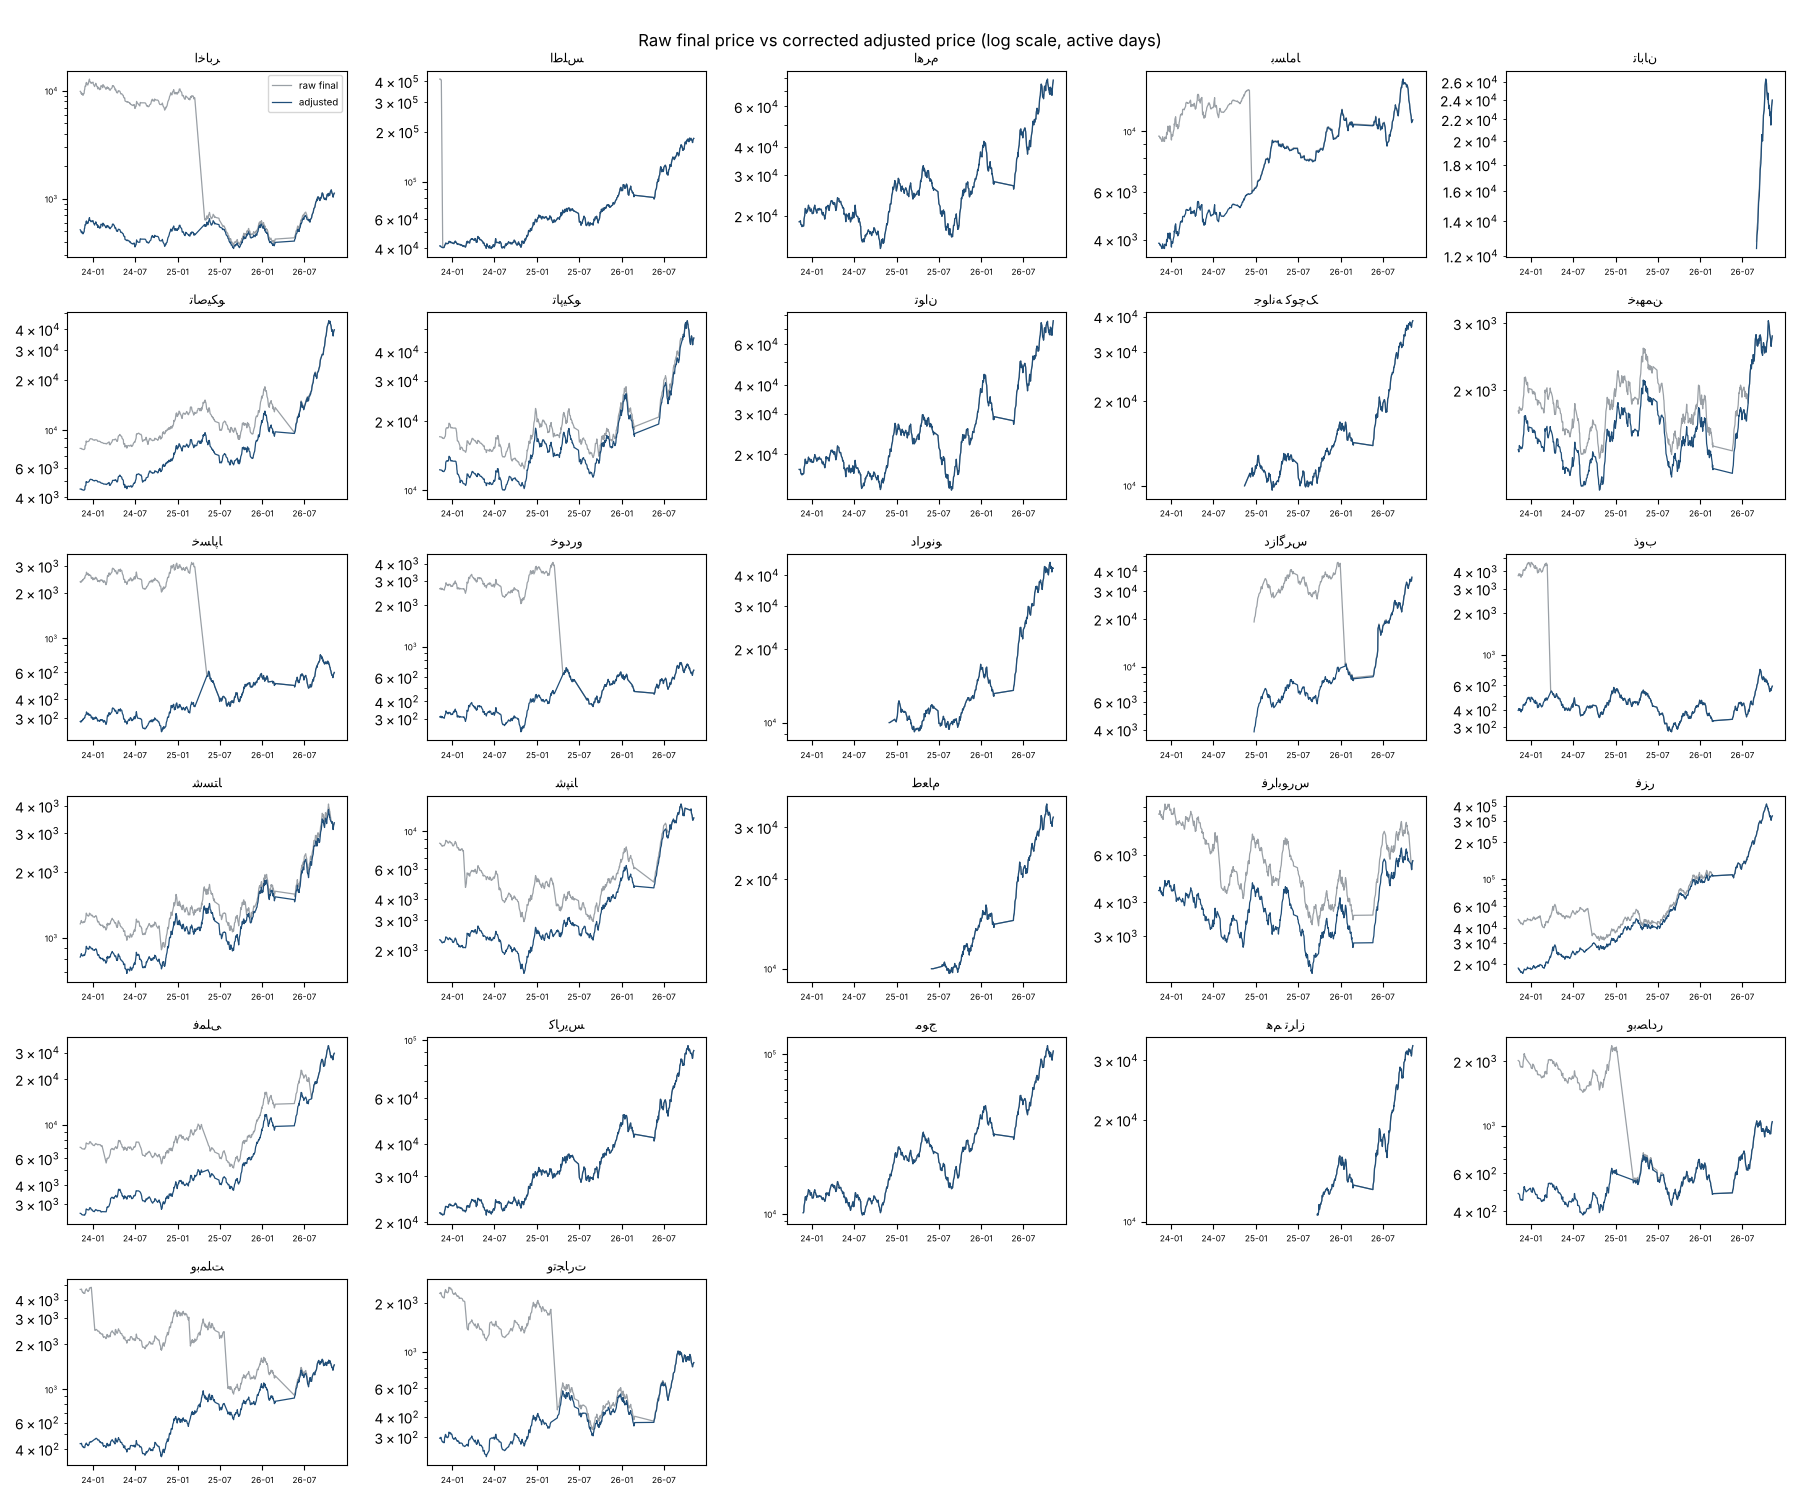

In [62]:
image("step5_profile/raw_vs_adjusted_price.png")

## Step 6a - Returns and features

### step6a_returns_features/summary.json

In [63]:
kv("step6a_returns_features/summary.json")

step6a_returns_features/summary.json


,value
rows,15847
active,14916
clean_returns,14861
extreme,20


### step6a_returns_features/checks_summary.csv

In [64]:
table("step6a_returns_features/checks_summary.csv")

step6a_returns_features/checks_summary.csv  [12 rows x 5 cols]


,id,check,status,n_issues,detail
0,S6A.01,market-closure days removed from the panel,PASS,0,"1521 rows removed, 15847 kept"
1,S6A.02,"returns are NaN on halted rows, pre-listing rows, first trade and price-anom...",PASS,0,14889 valid returns of 14916 active rows; halted rows never get 0
2,S6A.03,"return equals final/prev_final-1 on ordinary rows (non-event, previous recor...",PASS,0,max deviation 6.5e-07 on 14741 rows; 119 reopen rows differ by up to 3.3e-03...
3,S6A.04,clean returns beyond the period band (+1.5%),WARN,20,20 rows (0.13% of clean returns); 17 are reopen rows
4,S6A.05,no look-ahead: perturbing today's value/return leaves today's rolling baseli...,PASS,0,tested on 3 symbols
5,S6A.06,flow features exist only where real/legal columns exist,INFO,NaN,ind_buy_share non-NaN on 14916 of 14916 active rows
6,S6A.07,no infinite values in features,PASS,0,NaN
7,S6A.08,clean return distribution,INFO,"14,861","n=14861, std=0.0214, p01=-0.040, p99=0.039, kurtosis=3.3, skew=0.19"
8,S6A.09,returns kept in 'ret' but removed from 'ret_clean',INFO,28,"15 after >10-day halts, 13 share-increase reopens, 7 after a missing record"
9,S6A.10,daily volatility by symbol (clean returns),INFO,NaN,"min 0.0154 (بساما), median 0.0210, max 0.0285 (دزاگرس)"


### step6a_returns_features/coverage_by_symbol.csv

In [65]:
table("step6a_returns_features/coverage_by_symbol.csv")

step6a_returns_features/coverage_by_symbol.csv  [27 rows x 8 cols]


,symbol,active_rows,clean_ret,vol20,value_rel20,advol_rel20,flows,clean_ret_share
0,اخابر,607,605,595,597,597,607,0.99671
1,اطلس,655,652,642,645,645,655,0.99542
2,اهرم,659,658,648,649,649,659,0.99848
3,بساما,638,635,625,628,587,638,0.9953
4,تابان,47,46,36,37,37,47,0.97872
5,تاصيكو,639,638,628,629,629,639,0.99844
6,تاپيكو,626,624,614,616,616,626,0.99681
7,توان,658,656,646,648,648,658,0.99696
8,جوانه كوچك,405,403,393,395,395,405,0.99506
9,خبهمن,636,635,625,626,626,636,0.99843


### step6a_returns_features/extreme_returns.csv

In [66]:
table("step6a_returns_features/extreme_returns.csv")

step6a_returns_features/extreme_returns.csv  [20 rows x 7 cols]


,symbol,date,ret_clean,band_cap,halt_len,is_reopen,adj_event
0,تابان,2026-09-23,0.097451,0.04,2,True,True
1,تاصيكو,2026-07-08,0.11314,0.04,4,True,False
2,تاصيكو,2026-09-16,0.080658,0.04,5,True,True
3,تاپيكو,2026-08-18,0.06001,0.04,1,True,False
4,تاپيكو,2026-09-19,0.060418,0.04,4,True,False
5,توان,2026-11-07,0.055338,0.04,0,False,False
6,خبهمن,2026-07-26,0.079456,0.04,3,True,True
7,خساپا,2025-06-29,-0.16875,0.03,2,True,False
8,خساپا,2026-07-19,-0.083467,0.04,3,True,False
9,خودرو,2024-11-19,0.063066,0.03,1,True,False


### step6a_returns_features/feature_correlations.csv

In [67]:
table("step6a_returns_features/feature_correlations.csv")

step6a_returns_features/feature_correlations.csv  [6 rows x 7 cols]


,index,ret_clean,hl_range,value_rel20,tcount_rel20,ind_net_ratio,abs_ret
0,ret_clean,1,-0.16888,0.13585,-0.020899,0.53797,0.14021
1,hl_range,-0.16888,1,0.29456,0.48147,-0.12501,-0.26928
2,value_rel20,0.13585,0.29456,1,0.82599,0.11822,0.11794
3,tcount_rel20,-0.020899,0.48147,0.82599,1,-0.00030897,-0.045006
4,ind_net_ratio,0.53797,-0.12501,0.11822,-0.00030897,1,0.24447
5,abs_ret,0.14021,-0.26928,0.11794,-0.045006,0.24447,1


### step6a_returns_features/feature_summary.csv

In [68]:
table("step6a_returns_features/feature_summary.csv")

step6a_returns_features/feature_summary.csv  [12 rows x 10 cols]


,feature,n,share_nan_all_rows,mean,std,p01,p05,p50,p95,p99
0,ret_clean,14861,0.06222,0.0023335,0.021366,-0.040397,-0.030041,0.0012587,0.029517,0.03932
1,hl_range,14916,0.058749,0.026798,0.017576,0,0,0.026099,0.057264,0.068079
2,vol20,14591,0.079258,0.019393,0.0062466,0.004614,0.0089777,0.019597,0.029158,0.034845
3,vol60,14051,0.11333,0.020268,0.0051966,0.0069677,0.011375,0.020447,0.028808,0.033275
4,log_value,14916,0.058749,26.678,1.8864,21.467,23.442,26.714,29.642,30.484
5,value_rel20,14646,0.075787,1.5942,3.0693,0.026627,0.18113,0.99772,4.4459,10.488
6,tcount_rel20,14646,0.075787,1.3184,1.7109,0.054291,0.18681,0.97103,3.2982,7.1296
7,advol_rel20,14523,0.083549,1.5042,2.8246,0.025552,0.17824,0.98377,4.0395,9.6813
8,ind_buy_share,14916,0.058749,0.63928,0.27993,0.021662,0.11014,0.70728,0.98841,1
9,ind_net_ratio,14916,0.058749,-0.061081,0.35092,-0.88485,-0.65852,-0.046737,0.58552,0.84512


### step6a_returns_features/features_daily.csv

In [69]:
table("step6a_returns_features/features_daily.csv")

step6a_returns_features/features_daily.csv  [15847 rows x 35 cols]


,symbol,date,active,pre_listing,first_trade,is_reopen,halt_len,after_gap,adj_event,reopen_share_increase,price_anomaly,volume_adj_uncertain,ret,ret_last,ret_clean,ret_extreme,band_cap,hl_range,intraday_ret,vol20,vol60,park20,range_rel20,log_value,value_rel20,log_value_rel20,tcount_rel20,advol_rel20,avg_trade_value,limit_locked,ind_buy_share,ind_sell_share,ind_net_ratio,ind_power_ratio,log_ind_power
0,اخابر,2023-11-08,True,False,True,False,NaN,False,False,False,False,False,NaN,NaN,NaN,False,0.1,0.030275,0.0071465,NaN,NaN,NaN,NaN,26.254,NaN,NaN,NaN,NaN,1.5776e+08,False,0.88508,0.58578,0.29929,1.6066,0.47415
1,اخابر,2023-11-11,True,False,False,False,0,False,False,False,False,False,-0.01833,-0.025761,-0.01833,False,0.1,0.054122,-0.037895,NaN,NaN,NaN,NaN,25.997,NaN,NaN,NaN,NaN,9.7039e+07,False,0.83022,0.83783,-0.0076175,0.91828,-0.085257
2,اخابر,2023-11-12,True,False,False,False,0,False,False,False,False,False,-0.028142,-0.018968,-0.028142,False,0.1,0.034686,-0.029352,NaN,NaN,NaN,NaN,25.81,NaN,NaN,NaN,NaN,9.8877e+07,False,0.92693,0.91061,0.016318,0.71689,-0.33283
3,اخابر,2023-11-13,True,False,False,False,0,False,False,False,False,False,0.0052715,-0.0053333,0.0052715,False,0.1,0.050431,-0.026387,NaN,NaN,NaN,NaN,25.836,NaN,NaN,NaN,NaN,1.1619e+08,False,0.88808,0.76473,0.12335,0.77809,-0.25091
4,اخابر,2023-11-14,True,False,False,False,0,False,False,False,False,False,-0.023405,-0.014001,-0.023405,False,0.1,0.043064,-0.0097141,NaN,NaN,NaN,NaN,26.121,NaN,NaN,NaN,NaN,1.501e+08,False,0.70268,0.86257,-0.1599,0.67564,-0.39209
5,اخابر,2023-11-15,True,False,False,False,0,False,False,False,False,False,0.0213,0.019335,0.0213,False,0.1,0.050858,0.021506,NaN,NaN,NaN,NaN,26.291,NaN,NaN,NaN,NaN,1.6293e+08,False,0.82451,0.6542,0.17032,1.1455,0.13586
6,اخابر,2023-11-18,True,False,False,False,0,False,False,False,False,False,-0.0052826,-0.017168,-0.0052826,False,0.1,0.041385,-0.034046,NaN,NaN,NaN,NaN,25.693,NaN,NaN,NaN,NaN,1.1242e+08,False,0.89822,0.66251,0.23571,0.99292,-0.0071063
7,اخابر,2023-11-19,True,False,False,False,0,False,False,False,False,False,-0.018173,-0.009788,-0.018173,False,0.1,0.050413,-0.009788,NaN,NaN,NaN,NaN,25.564,NaN,NaN,NaN,NaN,8.6547e+07,False,0.94798,0.73389,0.21409,0.77403,-0.25615
8,اخابر,2023-11-20,True,False,False,False,0,False,False,False,False,False,-0.019608,-0.0087816,-0.019608,False,0.1,0.026288,-0.0033021,NaN,NaN,NaN,NaN,25.597,NaN,NaN,NaN,NaN,1.2426e+08,False,0.83896,0.84891,-0.0099577,1.01,0.009907
9,اخابر,2023-11-21,True,False,False,False,0,False,False,False,False,False,0.028201,0.022889,0.028201,False,0.1,0.057894,0.023992,NaN,NaN,NaN,NaN,26.415,NaN,NaN,NaN,NaN,1.6427e+08,False,0.96519,0.50259,0.4626,1.4707,0.38572


### step6a_returns_features/leakage_check.csv

In [70]:
table("step6a_returns_features/leakage_check.csv")

step6a_returns_features/leakage_check.csv  [3 rows x 4 cols]


,symbol,row,median_unchanged,vol_unchanged
0,خودرو,210,True,True
1,اخابر,210,True,True
2,ذوب,213,True,True


### step6a_returns_features/feature_coverage.png

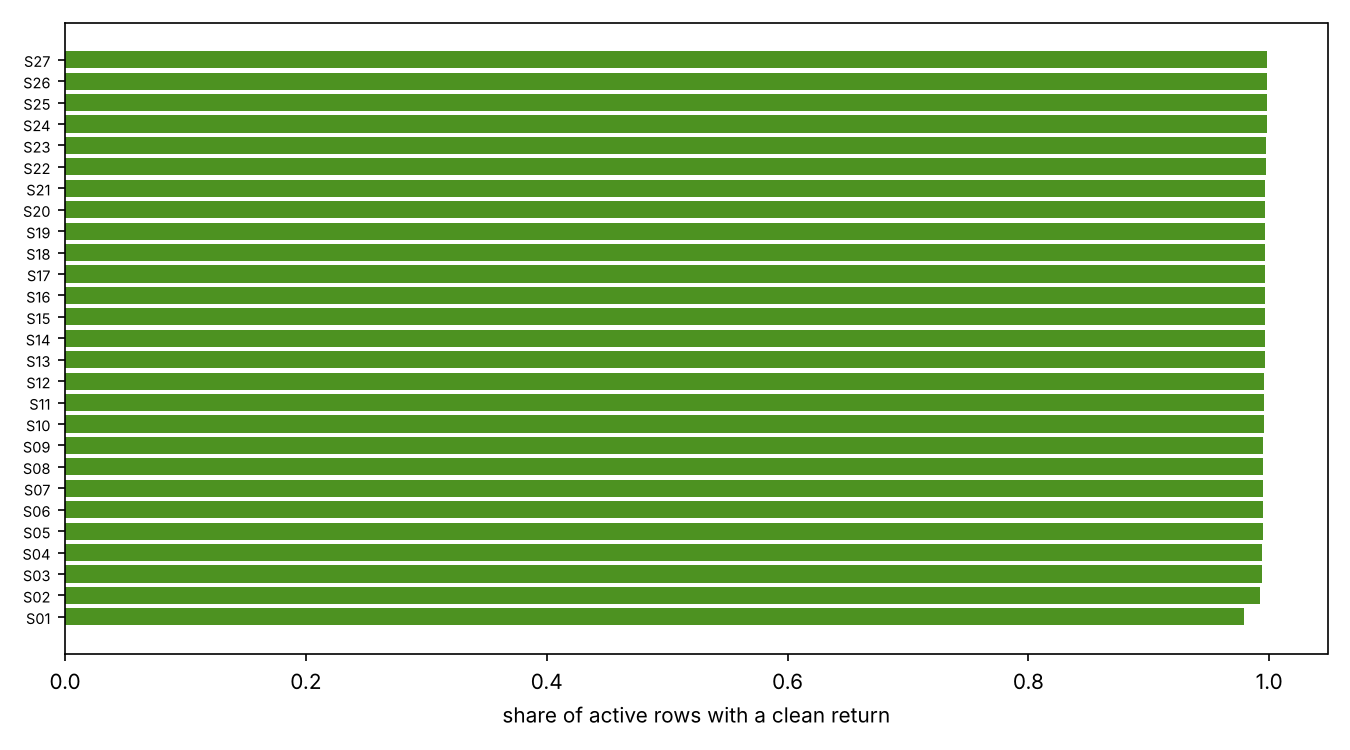

In [71]:
image("step6a_returns_features/feature_coverage.png")

### step6a_returns_features/return_hist.png

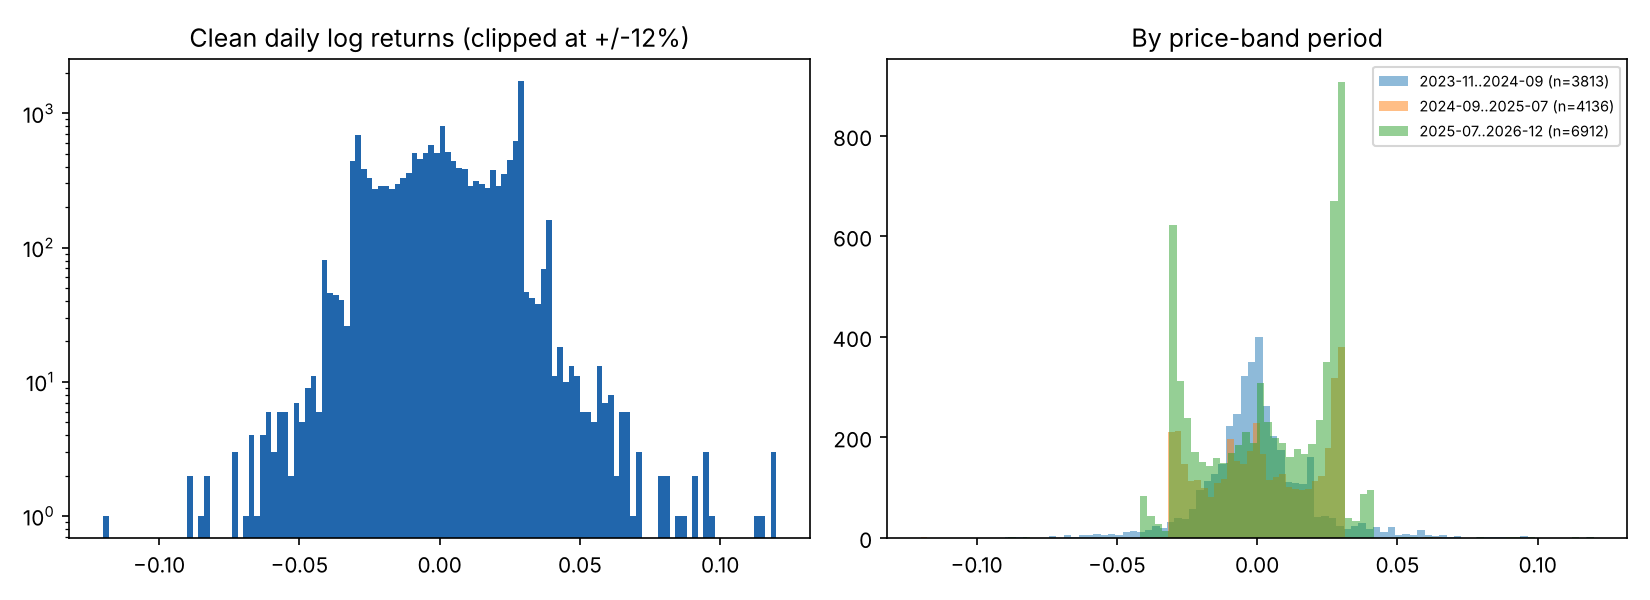

In [72]:
image("step6a_returns_features/return_hist.png")

## Step 6b - Return distribution and risk

### step6b_distribution/summary.json

In [73]:
kv("step6b_distribution/summary.json")

step6b_distribution/summary.json


,value
symbols,27
jb_rejected,23
INFO,7


### step6b_distribution/checks_summary.csv

In [74]:
table("step6b_distribution/checks_summary.csv")

step6b_distribution/checks_summary.csv  [7 rows x 5 cols]


,id,check,status,n_issues,detail
0,S6B.01,Jarque-Bera normality test on clean returns,INFO,23,"normality rejected for 23/27 symbols (n>=30); median skew -0.04, median exce..."
1,S6B.02,skewness sign across symbols,INFO,NaN,"12/27 symbols right-skewed, 15 left-skewed"
2,S6B.03,days closing at the daily price limit (last_price vs reference),INFO,"2,102",P2 (+-3%): 38.3% of 4150 symbol-days; P3 (+-4%): 7.4% of 6919; limit-up 1245...
3,S6B.04,maximum drawdown of the adjusted price,INFO,NaN,"median -38.8%; worst: موج -55.8%, فرابورس -54.7%, توان -52.9%; 3/27 symbols ..."
4,S6B.05,"ADF test (5%): log adjusted price is non-stationary, returns are stationary",INFO,NaN,price: unit root not rejected for 26/26 symbols; returns: stationary for 26/...
5,S6B.06,partial autocorrelation of clean returns (median over symbols),INFO,NaN,lag1: +0.343; lag2: +0.006; lag3: +0.087; lag4: -0.004; lag5: -0.013
6,S6B.07,cross-symbol median of quarterly daily volatility,INFO,NaN,"min 0.0137 (2023Q4), max 0.0248 (2026Q3)"


### step6b_distribution/acf_pacf_by_symbol.csv

In [75]:
table("step6b_distribution/acf_pacf_by_symbol.csv")

step6b_distribution/acf_pacf_by_symbol.csv  [26 rows x 22 cols]


,symbol,n,acf_1,acf_2,acf_3,acf_4,acf_5,acf_6,acf_7,acf_8,acf_9,acf_10,pacf_1,pacf_2,pacf_3,pacf_4,pacf_5,pacf_6,pacf_7,pacf_8,pacf_9,pacf_10
0,اخابر,605,0.31375,0.15874,0.15277,0.072528,0.008663,0.075973,0.069459,0.067401,0.019935,0.073419,0.31456,0.06825,0.09606,-0.009028,-0.03744,0.073666,0.029732,0.037806,-0.035615,0.064019
1,اطلس,652,0.25647,-0.038906,0.058279,-0.013958,-0.067127,-0.047093,-0.009871,-0.015635,-0.018651,0.10541,0.25669,-0.11202,0.10713,-0.071094,-0.035092,-0.032836,0.007852,-0.016425,-0.007974,0.11906
2,اهرم,658,0.37177,0.10249,0.13006,0.072919,-0.01165,-0.017036,0.013659,-0.013182,0.026448,0.09358,0.3741,-0.040837,0.12523,-0.016959,-0.045009,-0.009673,0.021322,-0.025496,0.059433,0.076267
3,بساما,635,0.34316,0.16759,0.12283,0.087258,0.038219,0.12357,-0.024515,-0.11393,-0.034949,0.014693,0.34332,0.056392,0.05641,0.024809,-0.013112,0.11756,-0.12255,-0.11058,0.037188,0.039708
4,تاصيكو,638,0.38449,0.16012,0.25969,0.17507,0.051596,0.056367,0.074135,0.068183,0.039809,0.039716,0.38541,0.01521,0.22917,-0.00019,-0.043291,-0.000757,0.024515,0.040856,-0.003048,0.005385
5,تاپيكو,624,0.42177,0.23726,0.19546,0.18136,0.12241,0.12421,0.040675,-0.033797,0.023901,0.027462,0.4231,0.072286,0.09005,0.072285,0.000249,0.051049,-0.0656,-0.079305,0.059462,0.00516
6,توان,656,0.38076,0.10797,0.11893,0.081881,0.006997,0.001692,0.012666,-0.026949,0.013701,0.094286,0.38326,-0.042742,0.1107,0.002428,-0.036242,0.003501,0.005238,-0.040218,0.052887,0.088001
7,جوانه كوچك,403,0.29909,0.031089,0.092696,0.033769,-0.022543,-0.086023,-0.028821,0.009668,0.026598,0.15105,0.29942,-0.064663,0.11416,-0.030436,-0.023061,-0.088392,0.02557,0.00919,0.039758,0.15417
8,خبهمن,635,0.27573,0.16649,0.13498,0.08657,0.040055,0.001155,-0.017328,-0.008938,-0.029263,0.037228,0.27644,0.097847,0.073144,0.022013,-0.01086,-0.030213,-0.025049,-0.000486,-0.022796,0.062445
9,خساپا,596,0.25875,0.10059,0.032582,0.021497,0.017589,0.03191,0.023353,0.050401,0.005003,0.043361,0.25935,0.036032,-0.001601,0.011608,0.008649,0.025155,0.008317,0.041597,-0.021601,0.043472


### step6b_distribution/distribution_by_symbol.csv

In [76]:
table("step6b_distribution/distribution_by_symbol.csv")

step6b_distribution/distribution_by_symbol.csv  [27 rows x 16 cols]


,symbol,n,mean,std,skew,excess_kurtosis,min,p01,p05,median,p95,p99,max,jb_stat,jb_p,normal_rejected_5pct
0,اخابر,605,0.000923,0.022338,0.089368,-0.66982,-0.067261,-0.043114,-0.029629,-0.001338,0.029136,0.053434,0.066115,12.115,0.00234,True
1,اطلس,652,0.002301,0.017247,0.13676,-0.028026,-0.040474,-0.030453,-0.028351,0.000977,0.029543,0.029557,0.08402,2.0538,0.35811,False
2,اهرم,658,0.002164,0.025406,-0.032763,-0.70328,-0.072057,-0.04082,-0.038643,0.001731,0.039132,0.043746,0.09531,13.678,0.001071,True
3,بساما,635,0.001631,0.015389,-0.287,1.2169,-0.0564,-0.040003,-0.02816,0.001241,0.026971,0.04261,0.047077,47.896,0,True
4,تابان,46,0.014337,0.026415,-0.10232,0.70716,-0.030397,-0.03017,-0.029673,0.028965,0.029485,0.066872,0.097451,1.0387,0.5949,False
5,تاصيكو,638,0.003421,0.018962,0.3149,1.2448,-0.048047,-0.030438,-0.028739,0.000573,0.029387,0.030104,0.11314,51.735,0,True
6,تاپيكو,624,0.001957,0.019607,0.066891,-0.48535,-0.058998,-0.036428,-0.030096,0,0.029443,0.042619,0.060418,6.59,0.037068,True
7,توان,656,0.002281,0.025728,-0.082385,-0.66694,-0.073595,-0.040814,-0.039521,0.002867,0.03919,0.03944,0.095305,12.9,0.00158,True
8,جوانه كوچك,403,0.00312,0.019143,-0.25814,-1.1088,-0.03045,-0.030413,-0.029644,0.003948,0.029305,0.02955,0.029559,25.12,4e-06,True
9,خبهمن,635,0.001089,0.021629,0.055008,-0.49983,-0.06338,-0.04252,-0.030043,-0.000636,0.029439,0.047304,0.079456,6.9304,0.031266,True


### step6b_distribution/drawdown_by_symbol.csv

In [77]:
table("step6b_distribution/drawdown_by_symbol.csv")

step6b_distribution/drawdown_by_symbol.csv  [27 rows x 8 cols]


,symbol,n_days,max_drawdown,peak_date,trough_date,recovery_date,current_drawdown,longest_underwater_days
0,اخابر,607,-0.48321,2023-12-18,2025-08-30,2026-07-01,-0.06942,501
1,اطلس,655,-0.21995,2025-05-18,2025-08-13,2025-10-22,-0.00463,135
2,اهرم,659,-0.51239,2025-04-26,2025-08-26,2025-12-21,-0.01079,153
3,بساما,638,-0.30853,2026-09-26,2026-11-02,NaN,-0.2925,134
4,تابان,47,-0.18465,2026-10-10,2026-11-01,NaN,-0.08929,20
5,تاصيكو,639,-0.35752,2025-04-29,2025-08-30,2025-12-22,-0.11699,147
6,تاپيكو,626,-0.38767,2024-12-25,2025-08-30,2025-12-16,-0.15847,219
7,توان,658,-0.52894,2025-04-22,2025-08-25,2025-12-15,0,152
8,جوانه كوچك,405,-0.24786,2025-01-11,2025-03-11,2025-04-30,0,97
9,خبهمن,636,-0.44595,2025-04-30,2025-08-30,2026-08-02,-0.08858,242


### step6b_distribution/limit_days_by_symbol.csv

In [78]:
table("step6b_distribution/limit_days_by_symbol.csv")

step6b_distribution/limit_days_by_symbol.csv  [27 rows x 11 cols]


,symbol,P2_days,P2_limit_up,P2_limit_down,P2_limit_share,P2_locked_at_limit,P3_days,P3_limit_up,P3_limit_down,P3_limit_share,P3_locked_at_limit
0,اخابر,164,39,46,0.51829,21,262,0,0,0,0
1,اطلس,191,30,9,0.20419,11,277,0,0,0,0
2,اهرم,191,56,47,0.53927,30,277,102,63,0.59567,42
3,بساما,184,24,10,0.18478,9,269,0,0,0,0
4,تابان,0,0,0,NaN,0,46,0,0,0,0
5,تاصيكو,191,31,17,0.25131,7,261,0,0,0,0
6,تاپيكو,188,45,29,0.39362,28,253,0,0,0,0
7,توان,191,53,45,0.51309,29,277,99,64,0.58845,45
8,جوانه كوچك,128,25,25,0.39062,16,277,0,0,0,0
9,خبهمن,188,60,31,0.48404,26,271,0,0,0,0


### step6b_distribution/stationarity_by_symbol.csv

In [79]:
table("step6b_distribution/stationarity_by_symbol.csv")

step6b_distribution/stationarity_by_symbol.csv  [27 rows x 9 cols]


,symbol,n_price,n_ret,adf_level_stat,adf_level_p,adf_level_lags,adf_ret_stat,adf_ret_p,adf_ret_lags
0,اخابر,607,605,-0.38008,0.91337,3,-10.601,0,2
1,اطلس,655,652,1.3775,0.99701,4,-6.4891,0,11
2,اهرم,659,658,0.12434,0.96768,3,-11.214,0,2
3,بساما,638,635,-1.3815,0.59111,8,-8.8835,0,7
4,تابان,47,46,NaN,NaN,NaN,NaN,NaN,NaN
5,تاصيكو,639,638,1.6644,0.99804,3,-9.4655,0,2
6,تاپيكو,626,624,0.60377,0.98771,17,-8.6909,0,3
7,توان,658,656,0.1405,0.96872,3,-11.316,0,2
8,جوانه كوچك,405,403,1.2231,0.99614,3,-9.4595,0,2
9,خبهمن,636,635,-1.0456,0.73626,3,-11.096,0,2


### step6b_distribution/volatility_by_quarter.csv

In [80]:
table("step6b_distribution/volatility_by_quarter.csv")

step6b_distribution/volatility_by_quarter.csv  [13 rows x 5 cols]


,quarter,median,q25,q75,n_symbols
0,2023Q4,0.01367,0.01076,0.01953,21
1,2024Q1,0.0171,0.01405,0.01953,21
2,2024Q2,0.01879,0.01669,0.02394,21
3,2024Q3,0.01821,0.01554,0.02165,21
4,2024Q4,0.02055,0.01849,0.02107,22
5,2025Q1,0.01968,0.01798,0.02154,23
6,2025Q2,0.02268,0.01961,0.02374,24
7,2025Q3,0.01983,0.01848,0.02205,25
8,2025Q4,0.01896,0.01649,0.02067,26
9,2026Q1,0.02343,0.02118,0.02502,26


### step6b_distribution/acf_pacf_median.png

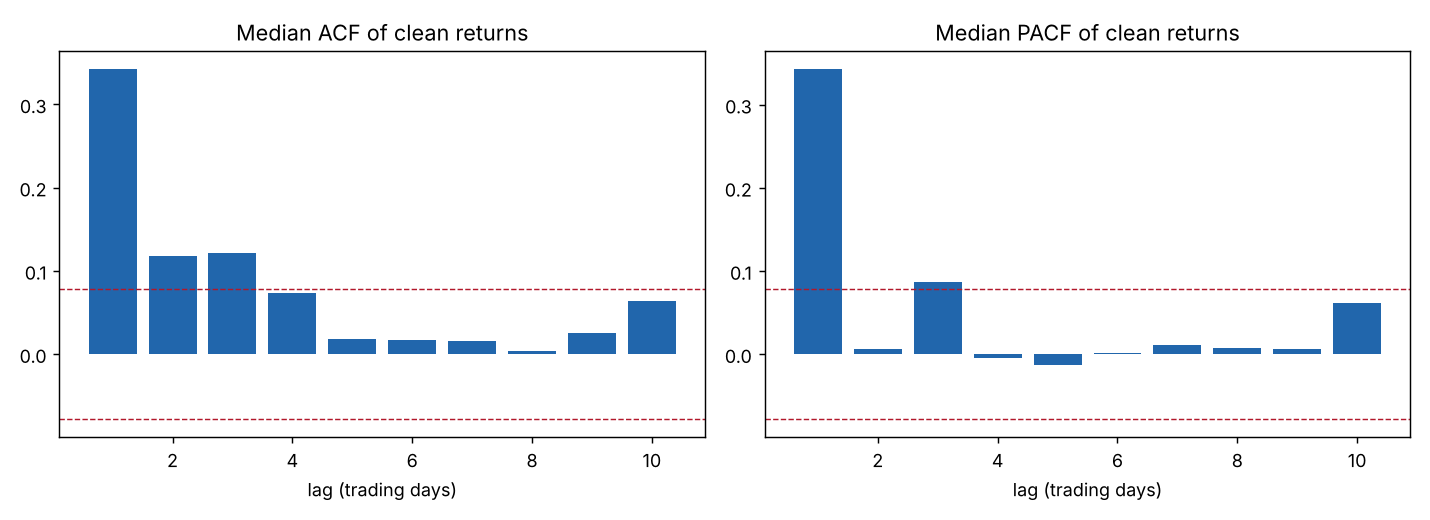

In [81]:
image("step6b_distribution/acf_pacf_median.png")

### step6b_distribution/drawdown_by_symbol.png

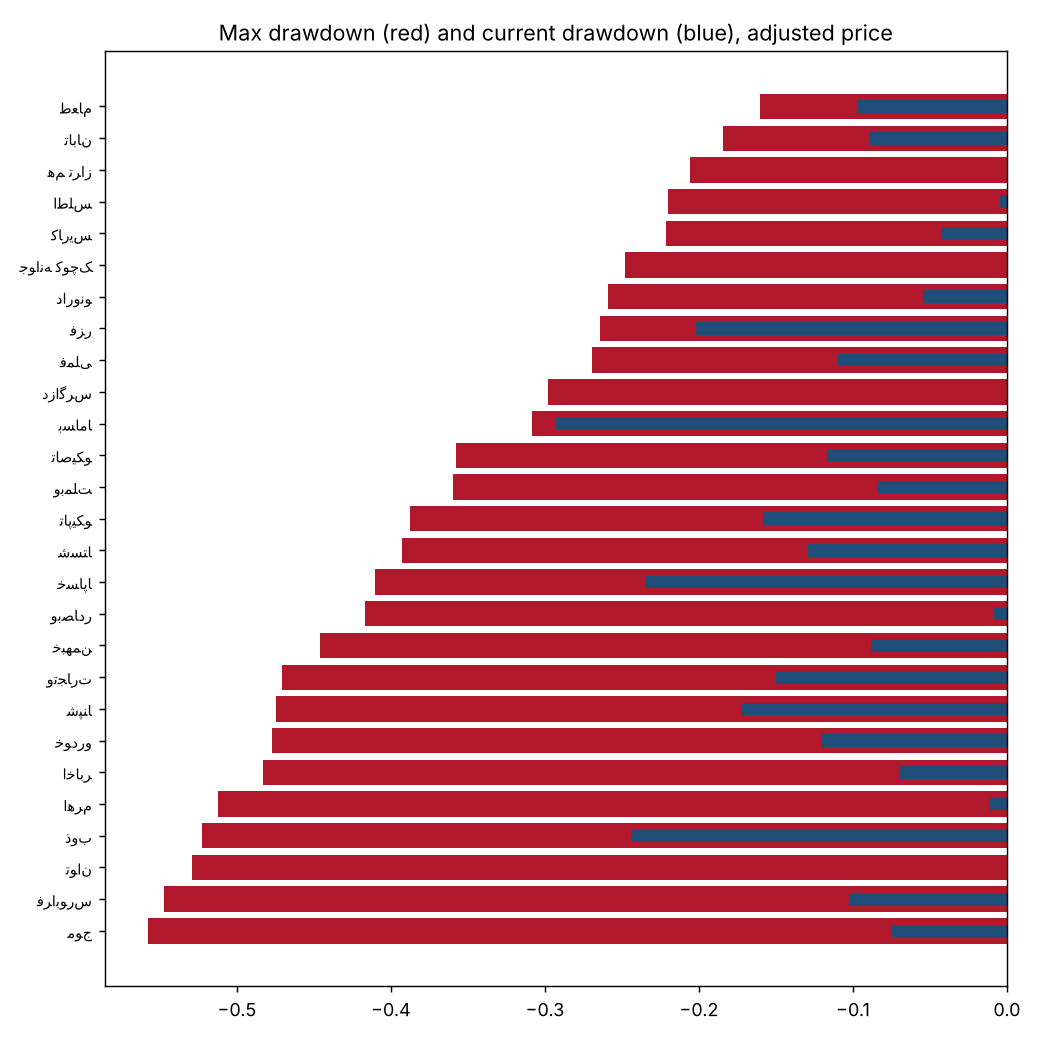

In [82]:
image("step6b_distribution/drawdown_by_symbol.png")

### step6b_distribution/return_qq_pooled.png

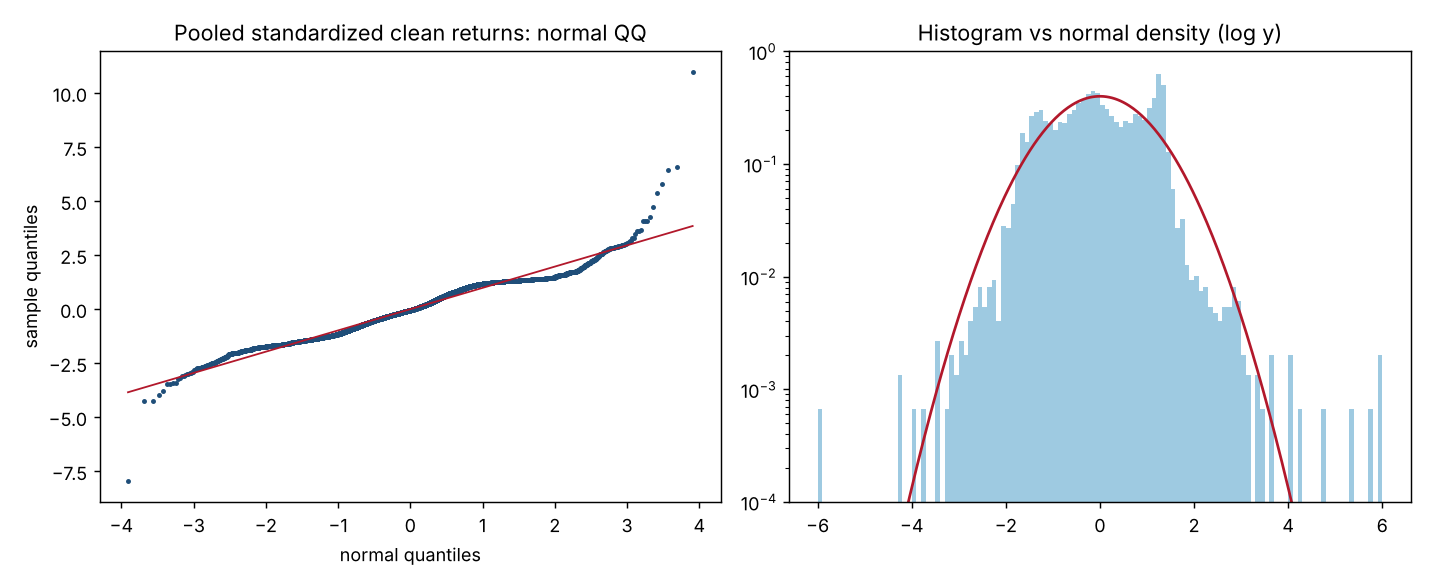

In [83]:
image("step6b_distribution/return_qq_pooled.png")

### step6b_distribution/volatility_by_quarter.png

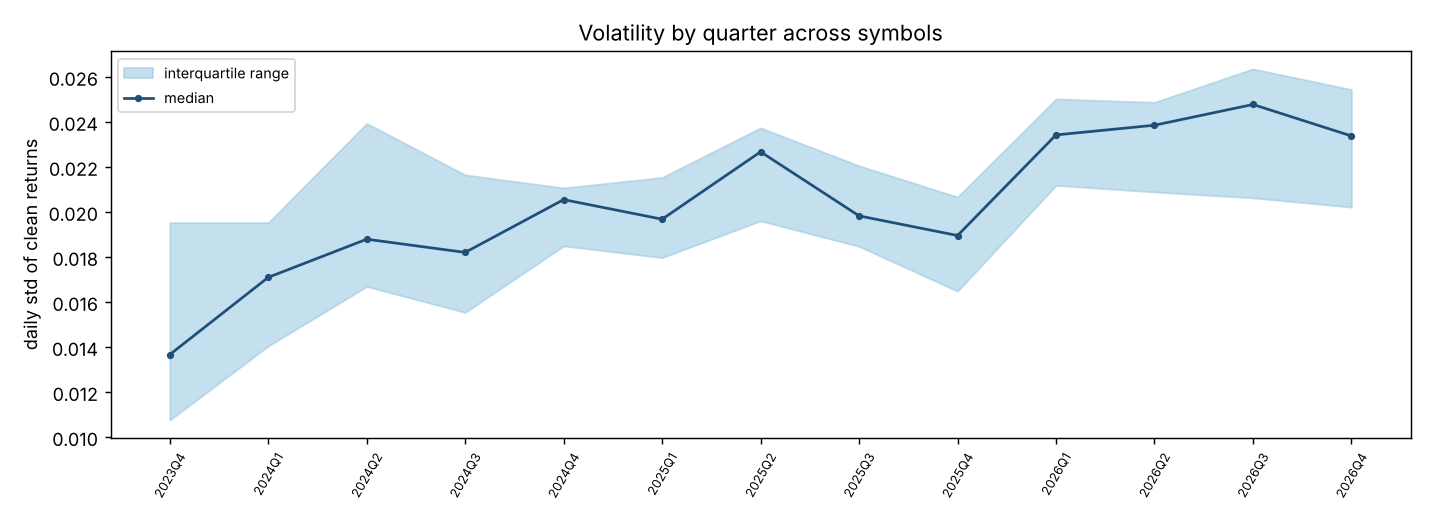

In [84]:
image("step6b_distribution/volatility_by_quarter.png")

## Step 6c - Return dynamics

### step6c_dynamics/summary.json

In [85]:
kv("step6c_dynamics/summary.json")

step6c_dynamics/summary.json


,value
symbols,27
lb_ret,26
lb_abs,25
arch,21


### step6c_dynamics/checks_summary.csv

In [86]:
table("step6c_dynamics/checks_summary.csv")

step6c_dynamics/checks_summary.csv  [12 rows x 5 cols]


,id,check,status,n_issues,detail
0,S6C.01,consecutive active pairs available for lead-lag tests,INFO,NaN,14734 pairs of 14916 active rows
1,S6C.02,"serial correlation of returns (Ljung-Box lag 10, 5%)",INFO,26,26/27 symbols reject no-autocorrelation; median acf1 = 0.348; 27 symbols hav...
2,S6C.03,"volatility clustering (Ljung-Box on |ret| and ARCH-LM(5), 5%)",INFO,25,"25/27 symbols reject for |ret|, 21/27 for ARCH-LM; median acf1 of |ret| = 0.232"
3,S6C.04,fat tails: excess kurtosis > 3 on clean returns,INFO,2,2/27 symbols; median excess kurtosis -0.50; range -1.13..38.80
4,S6C.11,lag-1 autocorrelation: final_price (VWAP-like) vs last_price basis,WARN,NaN,median acf1 0.348 on final_price returns vs 0.175 on last_price returns; 27/...
5,S6C.05,"weekday effects (Sat..Wed), symbol-demeaned",INFO,2,"Sat: ret -0.0000 (t=-0.1), |ret| x1.09 (t=7.0); Sun: ret -0.0012 (t=-2.9), |..."
6,S6C.06,daily volatility by price-band period (median across symbols),INFO,NaN,P1 to 2024-08: 0.0191; P2 2024-09..2025-06: 0.0207; P3 from 2025-07: 0.0229
7,S6C.12,next-day return on LAST-price basis (no VWAP artefact): strongest features,INFO,NaN,ret_clean: IC +0.245 (t=16.4); log_ind_power: IC +0.235 (t=13.2); ind_net_ra...
8,S6C.07,next-day RETURN (final_price basis): strongest feature rank-IC (mean over sy...,INFO,NaN,log_ind_power: IC +0.373 (t=16.6); ret_clean: IC +0.367 (t=26.1); ind_net_ra...
9,S6C.08,next-day |RETURN| (volatility): strongest features,INFO,NaN,abs_ret: IC +0.298 (t=17.2); vol20: IC +0.261 (t=14.6); vol60: IC +0.240 (t=...


### step6c_dynamics/autocorr_by_symbol.csv

In [87]:
table("step6c_dynamics/autocorr_by_symbol.csv")

step6c_dynamics/autocorr_by_symbol.csv  [27 rows x 24 cols]


,acf_last_1,acf_last_2,symbol,n,mean,std,skew,kurt,lb10_q,lb10_p,lb10_abs_q,lb10_abs_p,arch_lm5,arch_p,acf_ret_1,acf_abs_1,acf_ret_2,acf_abs_2,acf_ret_3,acf_abs_3,acf_ret_4,acf_abs_4,acf_ret_5,acf_abs_5
0,0.17971,0.14795,اخابر,605,0.00092317,0.02232,0.089368,-0.66982,105.56,0,106.97,0,16.228,0.0062215,0.31125,0.12784,0.16005,0.16147,0.15265,0.13625,0.074385,0.1402,0.02948,0.16743
1,0.12656,-0.018983,اطلس,652,0.0023011,0.017234,0.13676,-0.028026,58.708,6.3573e-09,202.18,0,28.507,2.8967e-05,0.25667,0.21991,-0.03863,0.21673,0.057837,0.15351,-0.012759,0.1675,-0.068614,0.17906
2,0.12165,0.1171,اهرم,658,0.002164,0.025387,-0.032763,-0.70328,119.92,0,158.03,0,33.938,2.4494e-06,0.37293,0.22993,0.10298,0.12946,0.13088,0.14344,0.073478,0.16053,-0.011747,0.16596
3,-0.052695,0.13227,بساما,635,0.0016315,0.015377,-0.287,1.2169,128.06,0,499.03,0,81.492,4.4409e-16,0.33172,0.41876,0.18514,0.34681,0.15467,0.30938,0.13276,0.26522,0.041999,0.19988
4,0.036336,0.38265,تابان,46,0.014337,0.026126,-0.10232,0.70716,NaN,NaN,NaN,NaN,NaN,NaN,0.36948,0.22807,0.40113,0.079516,0.43409,0.097578,0.33066,0.078787,0.29402,0.14657
5,0.16888,0.14708,تاصيكو,638,0.0034215,0.018947,0.3149,1.2448,186.72,0,629.87,0,35.538,1.1748e-06,0.40702,0.39701,0.1694,0.35155,0.25563,0.3409,0.201,0.34165,0.066338,0.32962
6,0.26238,0.15531,تاپيكو,624,0.0019573,0.019592,0.066891,-0.48535,213.47,0,596.78,0,81.393,4.4409e-16,0.43822,0.41209,0.23564,0.36324,0.18202,0.31259,0.16517,0.30162,0.12412,0.29384
7,0.17251,0.11729,توان,656,0.0022814,0.025708,-0.082385,-0.66694,123.72,0,216.23,0,39.088,2.2797e-07,0.38207,0.24058,0.10826,0.15419,0.12041,0.1406,0.082064,0.18067,0.006614,0.21847
8,0.11538,0.0072698,جوانه كوچك,403,0.00312,0.019119,-0.25814,-1.1088,54.086,4.6767e-08,50.353,2.2986e-07,30.508,1.1713e-05,0.29928,0.15643,0.03122,0.11123,0.093279,0.083733,0.034046,0.14945,-0.022768,0.081445
9,0.12838,0.11185,خبهمن,635,0.0010891,0.021612,0.055008,-0.49983,85.411,4.3299e-14,109.99,0,24.831,0.0001502,0.27517,0.23225,0.1651,0.1552,0.14646,0.14291,0.10237,0.12566,0.044472,0.1464


### step6c_dynamics/period_volatility.csv

In [88]:
table("step6c_dynamics/period_volatility.csv")

step6c_dynamics/period_volatility.csv  [27 rows x 4 cols]


,symbol,P1 to 2024-08,P2 2024-09..2025-06,P3 from 2025-07
0,اخابر,0.022323,0.02074,0.023207
1,اطلس,0.014256,0.016125,0.019557
2,اهرم,0.022791,0.021212,0.029355
3,بساما,0.01955,0.0083429,0.015884
4,تابان,NaN,NaN,0.026415
5,تاصيكو,0.012549,0.01634,0.023537
6,تاپيكو,0.015204,0.018448,0.022839
7,توان,0.022437,0.021661,0.029973
8,جوانه كوچك,NaN,0.019423,0.018903
9,خبهمن,0.020222,0.020517,0.023194


### step6c_dynamics/predictive_ic.csv

In [89]:
table("step6c_dynamics/predictive_ic.csv")

step6c_dynamics/predictive_ic.csv  [48 rows x 8 cols]


,feature,target,n,pooled_ic,mean_symbol_ic,t_over_symbols,share_symbols_positive,n_symbols
0,ret_clean,next_ret_last,14681,0.25105,0.24526,16.423,1,26
1,ret_clean,next_ret,14681,0.37117,0.36657,26.105,1,26
2,ret_clean,next_abs_ret,14681,0.080925,0.079332,7.6773,0.92308,26
3,ret_clean,next_range,14681,-0.010927,-0.017922,-1.1761,0.42308,26
4,abs_ret,next_ret_last,14681,0.072649,0.076503,6.0473,0.88462,26
5,abs_ret,next_ret,14681,0.11913,0.12168,12.312,1,26
6,abs_ret,next_abs_ret,14681,0.34434,0.29836,17.161,1,26
7,abs_ret,next_range,14681,0.049204,0.043311,3.1813,0.76923,26
8,vol20,next_ret_last,14416,0.030192,0.043976,5.9264,0.92308,26
9,vol20,next_ret,14416,0.034627,0.050092,6.5474,0.88462,26


### step6c_dynamics/vol_persistence.csv

In [90]:
table("step6c_dynamics/vol_persistence.csv")

step6c_dynamics/vol_persistence.csv  [10 rows x 5 cols]


,feature,quintile,n,mean_next_abs_ret,mean_next_ret
0,vol20,1,2894,0.013383,0.0013122
1,vol20,2,2879,0.016148,0.002503
2,vol20,3,2876,0.017722,0.002073
3,vol20,4,2879,0.019232,0.0016965
4,vol20,5,2888,0.0216,0.0038817
5,value_rel20,1,2905,0.01789,0.00013661
6,value_rel20,2,2885,0.016929,0.0013214
7,value_rel20,3,2893,0.016974,0.0024528
8,value_rel20,4,2885,0.017685,0.0030398
9,value_rel20,5,2902,0.018533,0.0045532


### step6c_dynamics/weekday_effects.csv

In [91]:
table("step6c_dynamics/weekday_effects.csv")

step6c_dynamics/weekday_effects.csv  [5 rows x 6 cols]


,weekday,n,mean_ret_dm,t_ret,rel_abs_ret,t_abs
0,Sat,3022,-3.0036e-05,-0.071787,1.0932,7.0491
1,Sun,2966,-0.001172,-2.8631,1.0459,3.4988
2,Mon,2940,0.0015865,4.1653,1.0149,1.2509
3,Tue,3052,-7.3414e-06,-0.020518,0.93663,-5.5137
4,Wed,2881,-0.00037321,-0.97281,0.90684,-6.957


### step6c_dynamics/acf_pooled.png

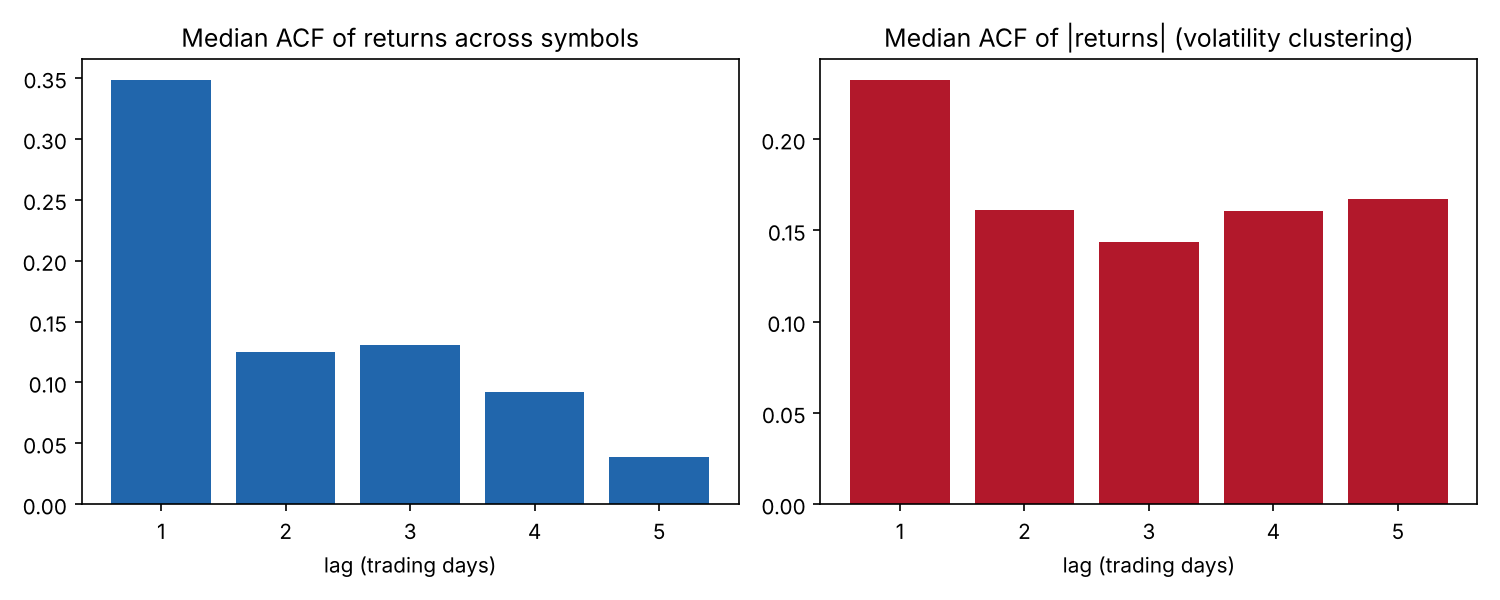

In [92]:
image("step6c_dynamics/acf_pooled.png")

### step6c_dynamics/predictive_ic.png

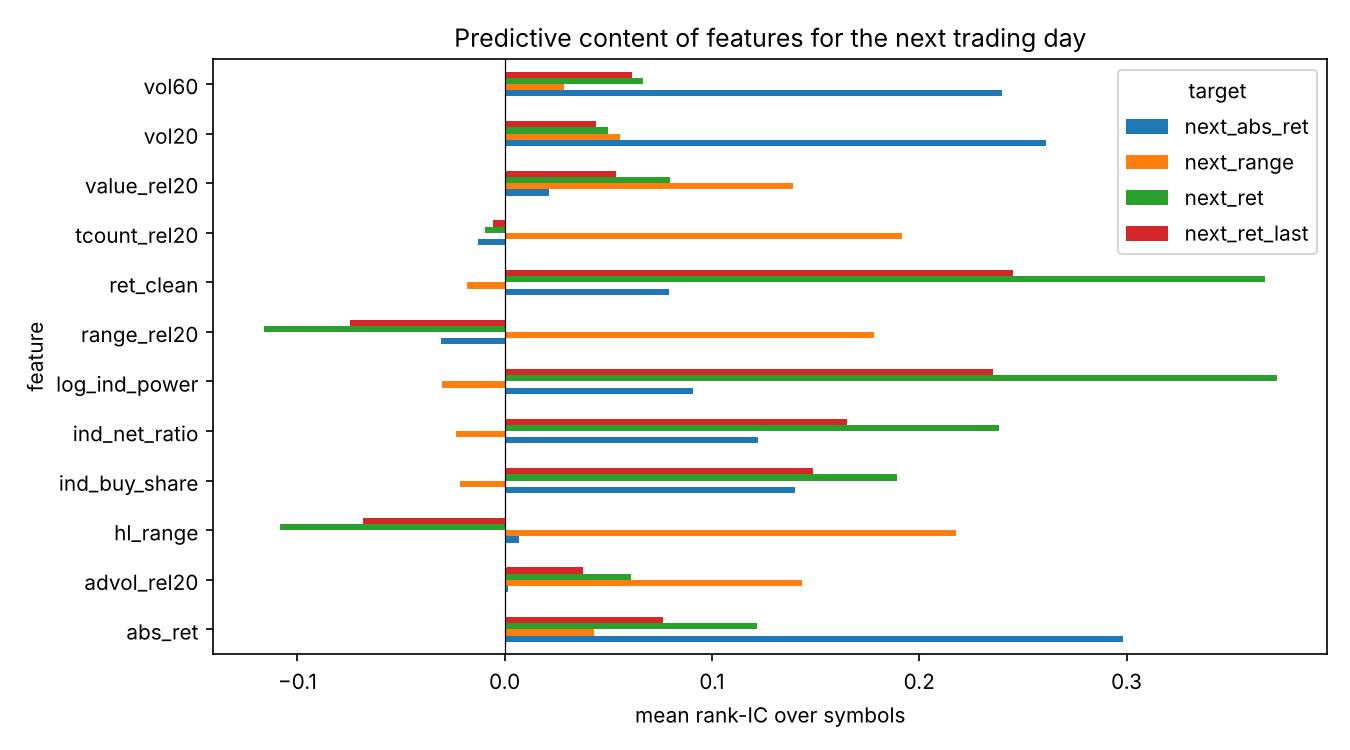

In [93]:
image("step6c_dynamics/predictive_ic.png")